# Acoustic leak sensitivity — within-run healthy → first leak → healthy

**Run notebook from:** `notebooks/`  
**Original untruncated CSVs:** `../data/2026-03-04/*.csv`  
**Results:** `../results/first_leak_frequency_sensitivity_ABA/`

This is an **A–B–A-style descriptive sensitivity analysis**, **not DiD** and not proof of causation. It uses the same experimental-run unit and healthy-plateau reproducibility concepts as `healthy_frequency_reproducibility_v2.ipynb`:
- Distinguish **within-run temporal SD** from **between-run differences in healthy baseline**.
- Do **not** combine different experiments into a synthetic representative spectrum.
- Do **not** treat timestamps as independent experimental replicates.
- Use exact observed Reynolds level **150**, with no smoothing, tolerance matching, interpolation, or arbitrary frequency exclusions.
- Analyze **every available frequency** in each of four probes and synchronized differences `UUS-US`, `US-DS`, `DS-DDS`.

## How sensitivity is measured

For each experiment and acoustic feature (probe × frequency, or synchronized probe difference × frequency), compute phase medians:

- `B` = median healthy **before** the first leak
- `L` = median during the **first consecutive leak block**
- `A` = median healthy **after** that first leak (Reynolds level 150)

We report `L-B` (leak onset), `L-A` (leak vs later healthy), and `A-B` (healthy drift/recovery). To identify a leak plateau that is **distinct from both** healthy plateaus, use the *signed excursion beyond the interval spanned by B and A*:

\[
E = \begin{cases}
L-\max(B,A), & L>\max(B,A) \\
L-\min(B,A), & L<\min(B,A) \\
0, & \text{otherwise.}
\end{cases}
\]

The normalized excursion is `abs(E) / median(SD_healthy_before, SD_healthy_after)` when the denominator is defined and distinguishable from floating-point arithmetic noise. Near-zero denominators are marked **undefined**, not converted to huge numbers; the unscaled amplitude excursion is always retained. This is a **descriptive signal-to-temporal-noise ratio**, not a p-value. A zero excursion means the leak median lies between the two healthy medians; it does **not** prove no leak response. A large healthy `A-B` remains visible, not silently removed.

Rank all features by the **median normalized excursion across complete independent runs**, and display per-run signs, counts, healthy drift, absolute excursion, and pre-to-leak contrast. A frequency-level summary shows the strongest observed feature at each frequency but explicitly identifies that feature (selecting the maximum among seven features is exploratory). **No arbitrary significance cutoffs, data filters, or automatic declarations of statistical significance.**

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

DATA = Path('../data/2026-03-04')
OUT = Path('../results/first_leak_frequency_sensitivity_ABA')
REYNOLDS_LEVEL = 150.0
PROBES = ('UUS', 'US', 'DS', 'DDS')
PAIRS = (('UUS','US'), ('US','DS'), ('DS','DDS'))
PHASES = ('before', 'leak', 'after')
TOP_N_PLOTS = 10  # Visualization limit ONLY: all feature/frequency results are saved.
IMPORTANT_FEATURES = ('US-DS__f400', 'US-DS__f500', 'UUS-US__f630')

if not DATA.is_dir():
    raise FileNotFoundError(f'Original CSV directory not found: {DATA.resolve()}')
FILES = sorted(DATA.glob('*.csv'))
if not FILES:
    raise FileNotFoundError(f'No original CSV files under: {DATA.resolve()}')
OUT.mkdir(parents=True, exist_ok=True)
print('Original files:', len(FILES), '| input:', DATA.resolve())
print('Output:', OUT.resolve())

Original files: 20 | input: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/data/2026-03-04
Output: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/results/first_leak_frequency_sensitivity_ABA


## 1. Read each original file, identify the first consecutive leak block, and label the three periods

Exactly as in `extract_through_first_leak.py`, the first leak ends when the initial uninterrupted `Leak Event = 1` block ends. The additional after-period comes **only** from subsequent rows marked `Leak Event = 0` at Reynolds level 150. No later leak rows are used. The code prints per-file coverage; missing phases or frequencies are recorded, not guessed.

In [2]:
def probe_name(stem):
    match = re.match(r'^(UUS|DDS|US|DS)(?=\d|_|-|$)', stem, flags=re.I)
    if not match:
        raise ValueError(f'Cannot infer probe from file name: {stem}')
    return match.group(1).upper()

pieces = []
file_inventory = []
all_frequencies = set()
for file in FILES:
    src = pd.read_csv(file, low_memory=False)
    src.columns = [re.split(r'[ǀ|｜¦]', str(c))[-1].strip() for c in src.columns]
    src = src.rename(columns={'Reynolds_Level': 'Reynolds_level'})
    if src.columns.duplicated().any():
        raise ValueError(f'{file.name}: duplicated normalized column names')
    required = ('Date-Time', 'Reynolds_level', 'Leak Event')
    missing = [c for c in required if c not in src]
    if missing:
        raise ValueError(f'{file.name}: missing {missing}')
    freq_cols = sorted((c for c in src.columns if re.fullmatch(r'f\d+(?:\.\d+)?', c)),
                       key=lambda x: float(x[1:]))
    if not freq_cols:
        raise ValueError(f'{file.name}: no acoustic frequency columns')
    all_frequencies.update(freq_cols)
    flags = pd.to_numeric(src['Leak Event'], errors='raise')
    levels = pd.to_numeric(src['Reynolds_level'], errors='raise')
    if flags.isna().any() or not flags.isin([0, 1]).all() or levels.isna().any():
        raise ValueError(f'{file.name}: invalid Leak Event or Reynolds_level values')
    timestamps = pd.to_datetime(src['Date-Time'], errors='raise')
    if timestamps.isna().any() or timestamps.duplicated().any():
        raise ValueError(f'{file.name}: missing or duplicate timestamps')
    leak_positions = np.flatnonzero(flags.to_numpy() == 1)
    if leak_positions.size == 0:
        first, stop = None, len(src)
    else:
        first = int(leak_positions[0]); stop = first
        while stop < len(src) and flags.iloc[stop] == 1:
            stop += 1
    probe = probe_name(file.stem)
    run_id = file.stem[len(probe):]

    before = (np.arange(len(src)) < (first if first is not None else len(src))) & flags.eq(0).to_numpy() & levels.eq(REYNOLDS_LEVEL).to_numpy()
    leak = np.zeros(len(src), dtype=bool)
    if first is not None:
        leak[first:stop] = True
    leak &= levels.eq(REYNOLDS_LEVEL).to_numpy()
    after = (np.arange(len(src)) >= stop) & flags.eq(0).to_numpy() & levels.eq(REYNOLDS_LEVEL).to_numpy()
    phase = np.full(len(src), '', dtype=object)
    phase[before] = 'before'; phase[leak] = 'leak'; phase[after] = 'after'
    selected = src.loc[phase != '', freq_cols].copy()
    for f in freq_cols:
        selected[f] = pd.to_numeric(selected[f], errors='coerce')
    selected['run_id'] = run_id
    selected['probe'] = probe
    selected['timestamp'] = timestamps.loc[phase != ''].to_numpy()
    selected['Reynolds_level'] = levels.loc[phase != ''].to_numpy()
    selected['phase'] = phase[phase != '']
    pieces.append(selected)
    file_inventory.append({
        'file': file.name, 'run_id': run_id, 'probe': probe,
        'first_leak_start_row': first, 'first_leak_end_exclusive': stop if first is not None else None,
        'n_before_Re150': int(before.sum()), 'n_first_leak_Re150': int(leak.sum()),
        'n_after_Re150': int(after.sum()), 'n_frequency_columns': len(freq_cols),
        'frequency_columns': ', '.join(freq_cols)
    })

FREQUENCIES = tuple(sorted(all_frequencies, key=lambda x:float(x[1:])))
inventory = pd.DataFrame(file_inventory).sort_values(['run_id','probe'])
inventory.to_csv(OUT/'phase_file_inventory.csv', index=False)
print('Available source frequencies:', len(FREQUENCIES), FREQUENCIES)
display(inventory[['file','n_before_Re150','n_first_leak_Re150','n_after_Re150','n_frequency_columns']])
raw = pd.concat(pieces, ignore_index=True)
# Preserve original per-file observations. A missing frequency column in a file remains missing.
for f in FREQUENCIES:
    if f not in raw.columns:
        raw[f] = np.nan
if raw.empty:
    raise ValueError('No Reynolds=150 data in the three requested phases')

Available source frequencies: 26 ('f25', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000')


,file,n_before_Re150,n_first_leak_Re150,n_after_Re150,n_frequency_columns
0,DDS1211_1.csv,600,600,300,26
5,DS1211_1.csv,600,600,300,26
10,US1211_1.csv,600,600,300,26
15,UUS1211_1.csv,600,600,300,26
1,DDS1212_1.csv,600,600,300,26
6,DS1212_1.csv,600,600,300,26
11,US1212_1.csv,600,600,300,26
16,UUS1212_1.csv,600,600,300,26
2,DDS1212_2.csv,600,600,300,26
7,DS1212_2.csv,600,600,300,26


## 2. Synchronize the four probes using real timestamps

The spatial differences are calculated at the **same observed timestamp within the same experiment**, not from separately averaged probe signals. We use exact inner joins and explicitly audit loss of observations. Phase and Reynolds-level disagreements between aligned probes are errors. No interpolation or synthetic spectra.

In [3]:
parts = []
for probe in PROBES:
    x = raw.loc[raw['probe'].eq(probe), ['run_id','timestamp','phase','Reynolds_level', *FREQUENCIES]].copy()
    if x.duplicated(['run_id','timestamp']).any():
        raise ValueError(f'{probe}: duplicate run/timestamp keys')
    x = x.rename(columns={c:f'{probe}__{c}' for c in ['phase','Reynolds_level',*FREQUENCIES]})
    parts.append(x)

wide = parts[0]
for x in parts[1:]:
    wide = wide.merge(x, on=['run_id','timestamp'], how='inner', validate='one_to_one')
if wide.empty:
    raise ValueError('No timestamps with all four probes present')
for probe in PROBES[1:]:
    if not wide[f'{PROBES[0]}__phase'].eq(wide[f'{probe}__phase']).all():
        raise ValueError(f'Conflicting phase labels between probes: {probe}')
    if not wide[f'{PROBES[0]}__Reynolds_level'].eq(wide[f'{probe}__Reynolds_level']).all():
        raise ValueError(f'Conflicting Reynolds levels between probes: {probe}')
wide['phase'] = wide[f'{PROBES[0]}__phase']
wide['Reynolds_level'] = wide[f'{PROBES[0]}__Reynolds_level']
for upstream, downstream in PAIRS:
    for f in FREQUENCIES:
        wide[f'{upstream}-{downstream}__{f}'] = wide[f'{upstream}__{f}'] - wide[f'{downstream}__{f}']
wide = wide.sort_values(['run_id','timestamp']).reset_index(drop=True)
FEATURES = [f'{p}__{f}' for p in PROBES for f in FREQUENCIES] + [
    f'{u}-{d}__{f}' for u,d in PAIRS for f in FREQUENCIES]

phase_coverage = (wide.groupby(['run_id','phase']).agg(
    synchronized_rows=('timestamp','size'),
    first_time=('timestamp','min'), last_time=('timestamp','max'))
    .reset_index())
phase_coverage.to_csv(OUT/'synchronized_phase_coverage.csv',index=False)
print('Synchronized rows:', len(wide), '| features:', len(FEATURES), '| runs:', wide.run_id.nunique())
print('Source rows excluded because not synchronized:', len(raw) - 4 * len(wide))
display(phase_coverage)

Synchronized rows: 7500 | features: 182 | runs: 5
Source rows excluded because not synchronized: 0


,run_id,phase,synchronized_rows,first_time,last_time
0,1211_1,after,300,2023-12-11 15:30:00,2023-12-11 15:34:59
1,1211_1,before,600,2023-12-11 15:10:00,2023-12-11 15:19:59
2,1211_1,leak,600,2023-12-11 15:20:00,2023-12-11 15:29:59
3,1212_1,after,300,2023-12-12 17:00:00,2023-12-12 17:04:59
4,1212_1,before,600,2023-12-12 16:40:00,2023-12-12 16:49:59
5,1212_1,leak,600,2023-12-12 16:50:00,2023-12-12 16:59:59
6,1212_2,after,300,2023-12-12 20:00:00,2023-12-12 20:04:59
7,1212_2,before,600,2023-12-12 19:40:00,2023-12-12 19:49:59
8,1212_2,leak,600,2023-12-12 19:50:00,2023-12-12 19:59:59
9,1213_1,after,300,2023-12-13 13:35:00,2023-12-13 13:39:59


## 3. Reuse the healthy reproducibility idea, then measure leak sensitivity

For every feature and independent experiment, calculate median and SD within each observed phase, plus `n` samples. **The SD is temporal variability, not between-run variability.** Compare `B`, `L`, and `A` from the *same run*. No significance test on autocorrelated timestamps.

For comparison with the healthy reproducibility notebook, compute **between-run SD of healthy-before run means** and **median within-run healthy-before SD** separately (do not use their ratio to hide baseline shifts).

In [4]:
per_run = []
for (run_id, phase), g in wide.groupby(['run_id','phase'], sort=True):
    row = {'run_id':run_id, 'phase':phase}
    for feature in FEATURES:
        x = g[feature].dropna()
        row[f'{feature}__n'] = len(x)
        row[f'{feature}__median'] = float(x.median()) if len(x) else np.nan
        row[f'{feature}__mean'] = float(x.mean()) if len(x) else np.nan
        row[f'{feature}__sd'] = float(x.std(ddof=1)) if len(x)>1 else np.nan
    per_run.append(row)
phase_stats = pd.DataFrame(per_run)
phase_stats.to_csv(OUT/'phase_run_feature_statistics_wide.csv',index=False)

rows = []
for run in sorted(wide.run_id.unique()):
    r = phase_stats.set_index(['run_id','phase'])
    for feature in FEATURES:
        record={'run_id':run, 'feature':feature,
                'frequency':feature.split('__',1)[1], 'channel':feature.split('__',1)[0]}
        for phase in PHASES:
            key=(run,phase)
            for stat in ('median','mean','sd','n'):
                record[f'{phase}_{stat}'] = r.at[key,f'{feature}__{stat}'] if key in r.index else (0 if stat=='n' else np.nan)
        b,l,a = record['before_median'],record['leak_median'],record['after_median']
        ok = (min(record['before_n'],record['leak_n'],record['after_n'])>0 and
              np.isfinite(b) and np.isfinite(l) and np.isfinite(a))
        record['complete_three_phases'] = bool(ok)
        if ok:
            record['leak_minus_before'] = l-b
            record['leak_minus_after'] = l-a
            record['after_minus_before'] = a-b
            record['excursion'] = l-max(b,a) if l>max(b,a) else (l-min(b,a) if l<min(b,a) else 0.0)
            noise = np.array([record['before_sd'],record['after_sd']], dtype=float)
            record['healthy_temporal_sd'] = float(np.median(noise)) if np.isfinite(noise).all() else np.nan
            # A spatial subtraction of nearly identical machine-precision values can have
            # a tiny nonzero numerical SD even when the healthy signal is constant.
            # This is a FLOATING-POINT guard, not an acoustic threshold or data filter.
            numerical_floor = 16 * np.finfo(float).eps * max(1.,abs(b),abs(l),abs(a))
            record['healthy_sd_at_numeric_floor'] = (
                not np.isfinite(record['healthy_temporal_sd']) or
                record['healthy_temporal_sd'] <= numerical_floor)
            record['scaled_onset'] = (abs(l-b)/record['before_sd']
                if np.isfinite(record['before_sd']) and record['before_sd'] > numerical_floor else np.nan)
            record['scaled_excursion'] = (abs(record['excursion'])/record['healthy_temporal_sd']
                if not record['healthy_sd_at_numeric_floor'] else np.nan)
            record['scaled_healthy_shift'] = (abs(a-b)/record['healthy_temporal_sd']
                if not record['healthy_sd_at_numeric_floor'] else np.nan)
        else:
            for metric in ('leak_minus_before','leak_minus_after','after_minus_before',
                           'excursion','healthy_temporal_sd','healthy_sd_at_numeric_floor','scaled_onset','scaled_excursion','scaled_healthy_shift'):
                record[metric] = np.nan
        rows.append(record)
run_feature = pd.DataFrame(rows)
run_feature.to_csv(OUT/'leak_sensitivity_by_run_feature.csv',index=False)
print('Complete run-feature triplets:',int(run_feature.complete_three_phases.sum()),'/',len(run_feature))
display(run_feature[['run_id','feature','before_median','leak_median','after_median',
                     'leak_minus_before','after_minus_before','excursion','scaled_excursion']].head(15))

Complete run-feature triplets: 910 / 910


,run_id,feature,before_median,leak_median,after_median,leak_minus_before,after_minus_before,excursion,scaled_excursion
0,1211_1,UUS__f25,24.946320,24.845219,24.783721,-0.101100,-0.162598,0.000000,0.000000
1,1211_1,UUS__f40,27.418278,27.595675,27.370435,0.177397,-0.047844,0.177397,0.081143
2,1211_1,UUS__f50,31.958413,31.664069,31.214444,-0.294344,-0.743969,0.000000,0.000000
3,1211_1,UUS__f63,34.020913,33.298521,32.891464,-0.722393,-1.129450,0.000000,0.000000
4,1211_1,UUS__f80,36.439818,35.370008,35.115125,-1.069810,-1.324693,0.000000,0.000000
5,1211_1,UUS__f100,33.347333,33.239029,33.068193,-0.108303,-0.279139,0.000000,0.000000
6,1211_1,UUS__f125,41.640692,41.345110,41.334585,-0.295581,-0.306106,0.000000,0.000000
7,1211_1,UUS__f160,32.838382,32.746920,33.102100,-0.091462,0.263718,-0.091462,0.067226
8,1211_1,UUS__f200,34.302032,34.485795,34.481458,0.183763,0.179426,0.004337,0.002764
9,1211_1,UUS__f250,45.584100,45.333818,44.956733,-0.250282,-0.627367,0.000000,0.000000


## 4. Rank features by reproducible leak excursion, **without p-values**

The primary sorting metric is the **median across independent runs** of the normalized excursion beyond both healthy plateaus. Also show the number of complete runs, the number of nonzero excursions, positive/negative direction counts, and the size of healthy drift. A high score from inconsistent runs or large healthy drift must be reviewed in the plots. All rows are exported, including zero/undefined scores.

In [5]:
feature_rows = []
for feature, g in run_feature.groupby('feature',sort=True):
    x = g[g.complete_three_phases]
    onset = x['leak_minus_before'].dropna()
    excursion = x['excursion'].dropna()
    normalized = x['scaled_excursion'].dropna()
    shifts = x['scaled_healthy_shift'].dropna()
    def median_or_nan(s):
        return float(s.median()) if not s.empty else np.nan
    pre = x[['run_id','before_mean','before_sd']].dropna(subset=['before_mean'])
    between_pre_sd = float(pre['before_mean'].std(ddof=1)) if len(pre)>1 else np.nan
    within_pre_sd = median_or_nan(pre['before_sd'].dropna())
    feature_rows.append({
        'feature':feature,'channel':feature.split('__')[0], 'frequency':feature.split('__')[1],
        'n_runs_complete':len(x), 'n_runs_normalized':len(normalized),
        'n_undefined_normalized':int(x['scaled_excursion'].isna().sum()),
        'n_positive_excursion':int((excursion>0).sum()),
        'n_negative_excursion':int((excursion<0).sum()),
        'n_zero_excursion':int(excursion.eq(0).sum()),
        'median_scaled_excursion':median_or_nan(normalized),
        'median_abs_excursion':median_or_nan(excursion.abs()),
        'median_leak_minus_before':median_or_nan(onset),
        'median_abs_leak_minus_before':median_or_nan(onset.abs()),
        'median_scaled_onset':median_or_nan(x['scaled_onset'].dropna()),
        'median_abs_healthy_shift':median_or_nan(x['after_minus_before'].abs().dropna()),
        'median_scaled_healthy_shift':median_or_nan(shifts),
        'between_run_sd_healthy_before_mean':between_pre_sd,
        'median_within_run_sd_healthy_before':within_pre_sd,
        'between_to_within_healthy_ratio':(
             between_pre_sd/within_pre_sd if np.isfinite(between_pre_sd) and
             np.isfinite(within_pre_sd) and within_pre_sd>0 else np.nan)
    })
ranking = pd.DataFrame(feature_rows).sort_values(
    ['median_scaled_excursion','n_runs_complete','median_abs_excursion'],
    ascending=[False,False,False],na_position='last').reset_index(drop=True)
ranking.insert(0,'rank_exploratory',np.arange(1,len(ranking)+1))
ranking.to_csv(OUT/'leak_sensitivity_feature_ranking.csv',index=False)
print('Top features (ALL rows saved; exploratory descriptive ranking only):')
display(ranking[['rank_exploratory','feature','n_runs_complete','n_runs_normalized','n_undefined_normalized','median_scaled_excursion',
                 'n_positive_excursion','n_negative_excursion','n_zero_excursion',
                 'median_abs_healthy_shift','median_scaled_healthy_shift',
                 'between_to_within_healthy_ratio']].head(25))

Top features (ALL rows saved; exploratory descriptive ranking only):


,rank_exploratory,feature,n_runs_complete,n_runs_normalized,n_undefined_normalized,median_scaled_excursion,n_positive_excursion,n_negative_excursion,n_zero_excursion,median_abs_healthy_shift,median_scaled_healthy_shift,between_to_within_healthy_ratio
0,1,DS__f2500,5,5,0,0.739616,3,0,2,0.112394,0.058027,3.427845
1,2,US-DS__f315,5,5,0,0.363005,2,2,1,0.348560,0.222057,2.908263
2,3,DS-DDS__f2500,5,5,0,0.324888,4,0,1,0.165795,0.108302,2.609334
3,4,UUS-US__f2500,5,5,0,0.279735,0,5,0,0.165802,0.158174,1.176547
4,5,US__f2500,5,5,0,0.246302,5,0,0,0.201210,0.135372,1.327747
5,6,US-DS__f2500,5,5,0,0.242717,4,1,0,0.109265,0.089022,3.173698
6,7,US__f3100,5,5,0,0.228154,3,1,1,0.237916,0.177588,1.263884
7,8,DS__f500,5,5,0,0.201551,3,2,0,0.335931,0.260209,1.385631
8,9,UUS-US__f3100,5,5,0,0.185527,2,3,0,0.065418,0.076529,1.512501
9,10,DS__f250,5,5,0,0.181136,2,2,1,0.169224,0.114567,5.570601


## 5. Summarize sensitivity **by frequency** and show every channel

A frequency produces seven possible features (four probes and three spatial differences). The frequency-level table reports which feature has the strongest descriptive response. **Choosing the maximum among channels is exploratory**: use the complete channel table and raw plots to avoid claiming a universally best frequency. No frequency is dropped simply because it is unstable across experiments.

,frequency_rank_exploratory,frequency,best_observed_feature,best_feature_median_scaled_excursion,best_feature_n_runs_complete,best_feature_positive_runs,best_feature_negative_runs,best_feature_zero_runs
0,1,f2500,DS__f2500,0.739616,5,3,0,2
1,2,f315,US-DS__f315,0.363005,5,2,2,1
6,3,f3100,US__f3100,0.228154,5,3,1,1
7,4,f500,DS__f500,0.201551,5,3,2,0
9,5,f250,DS__f250,0.181136,5,2,2,1
10,6,f630,UUS-US__f630,0.178664,5,2,3,0
13,7,f125,DS__f125,0.157289,5,0,3,2
14,8,f1250,UUS-US__f1250,0.154149,5,3,1,1
15,9,f100,UUS-US__f100,0.137345,5,2,2,1
17,10,f1000,US-DS__f1000,0.129889,5,3,2,0


US-DS — frequencies ranked at the probe pair bracketing the known leak:


,rank_within_channel,feature,n_runs_complete,median_scaled_excursion,n_positive_excursion,n_negative_excursion,n_zero_excursion,median_abs_excursion,median_abs_healthy_shift
1,1,US-DS__f315,5,0.363005,2,2,1,0.484699,0.348560
5,2,US-DS__f2500,5,0.242717,4,1,0,0.498551,0.109265
17,3,US-DS__f1000,5,0.129889,3,2,0,0.187482,0.147017
18,4,US-DS__f3100,5,0.128778,2,3,0,0.152921,0.256123
24,5,US-DS__f630,5,0.104151,3,2,0,0.115662,0.201207
29,6,US-DS__f100,5,0.086936,2,1,2,0.197218,0.212721
33,7,US-DS__f4000,5,0.081785,2,2,1,0.102724,0.120921
38,8,US-DS__f250,5,0.069889,3,1,1,0.121846,0.141764
57,9,US-DS__f800,5,0.045153,1,3,1,0.066861,0.110406
68,10,US-DS__f5000,5,0.033896,2,2,1,0.044271,0.043742


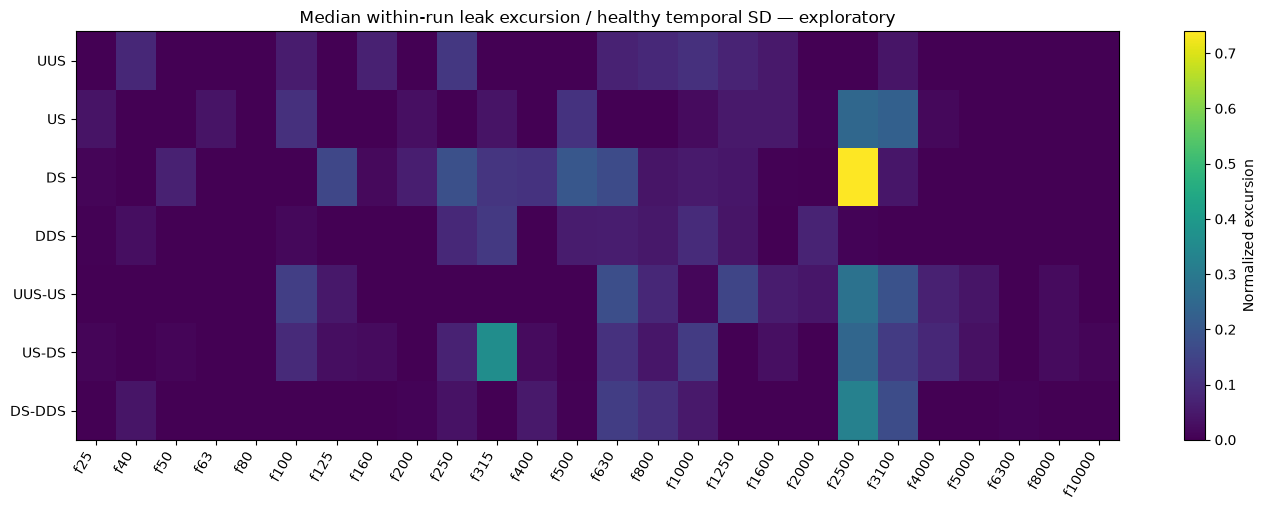

In [6]:
freq_best = (ranking.sort_values(['frequency','median_scaled_excursion'],ascending=[True,False],na_position='last')
             .drop_duplicates('frequency').copy())
freq_best = freq_best.rename(columns={
    'feature':'best_observed_feature', 'channel':'best_observed_channel',
    'median_scaled_excursion':'best_feature_median_scaled_excursion',
    'n_runs_complete':'best_feature_n_runs_complete',
    'n_positive_excursion':'best_feature_positive_runs',
    'n_negative_excursion':'best_feature_negative_runs',
    'n_zero_excursion':'best_feature_zero_runs'})
freq_best = freq_best.sort_values('best_feature_median_scaled_excursion',ascending=False,na_position='last')
freq_best.insert(0,'frequency_rank_exploratory',np.arange(1,len(freq_best)+1))
freq_best.to_csv(OUT/'leak_sensitivity_frequency_ranking.csv',index=False)
display(freq_best[['frequency_rank_exploratory','frequency','best_observed_feature',
                   'best_feature_median_scaled_excursion','best_feature_n_runs_complete',
                   'best_feature_positive_runs','best_feature_negative_runs','best_feature_zero_runs']])

# Keep physically relevant US-DS frequencies visible instead of allowing another
# channel to dominate the exploratory best-of-seven frequency ranking.
per_channel = ranking.sort_values(['channel','median_scaled_excursion'],
                                  ascending=[True,False],na_position='last').copy()
per_channel.insert(0,'rank_within_channel',per_channel.groupby('channel').cumcount()+1)
per_channel.to_csv(OUT/'leak_sensitivity_rankings_by_channel.csv',index=False)
print('US-DS — frequencies ranked at the probe pair bracketing the known leak:')
display(per_channel.loc[per_channel.channel.eq('US-DS'),[
    'rank_within_channel','feature','n_runs_complete','median_scaled_excursion',
    'n_positive_excursion','n_negative_excursion','n_zero_excursion',
    'median_abs_excursion','median_abs_healthy_shift']].head(26))

channels = [*PROBES,*(f'{a}-{b}' for a,b in PAIRS)]
score_matrix = ranking.pivot(index='channel',columns='frequency',values='median_scaled_excursion')
score_matrix = score_matrix.reindex(index=channels,columns=FREQUENCIES)
fig,ax=plt.subplots(figsize=(max(14,len(FREQUENCIES)*0.48),5.2))
image=ax.imshow(score_matrix.to_numpy(dtype=float),aspect='auto',interpolation='nearest')
ax.set_yticks(np.arange(len(channels)),channels)
ax.set_xticks(np.arange(len(FREQUENCIES)),FREQUENCIES,rotation=60,ha='right')
ax.set_title('Median within-run leak excursion / healthy temporal SD — exploratory')
fig.colorbar(image,ax=ax,label='Normalized excursion')
fig.tight_layout()
fig.savefig(OUT/'sensitivity_heatmap_all_frequencies.png',dpi=160,bbox_inches='tight')
plt.show()

## 6. Boxplots and direct time traces for the leading candidates and three previously discussed features

The plots retain **every observation**. Each run shows `healthy BEFORE`, `FIRST leak`, and `healthy AFTER`. Time series use the actual timestamps and make plateau drift and delayed recovery visible; boxplots alone do not establish a stable plateau. The `TOP_N_PLOTS` setting affects figures only, not calculation, export, or ranking.

Features plotted: ['DS__f2500', 'US-DS__f315', 'DS-DDS__f2500', 'UUS-US__f2500', 'US__f2500', 'US-DS__f2500', 'US__f3100', 'DS__f500', 'UUS-US__f3100', 'DS__f250', 'US-DS__f400', 'US-DS__f500', 'UUS-US__f630']
Feature ranking CSV contains: 182 features


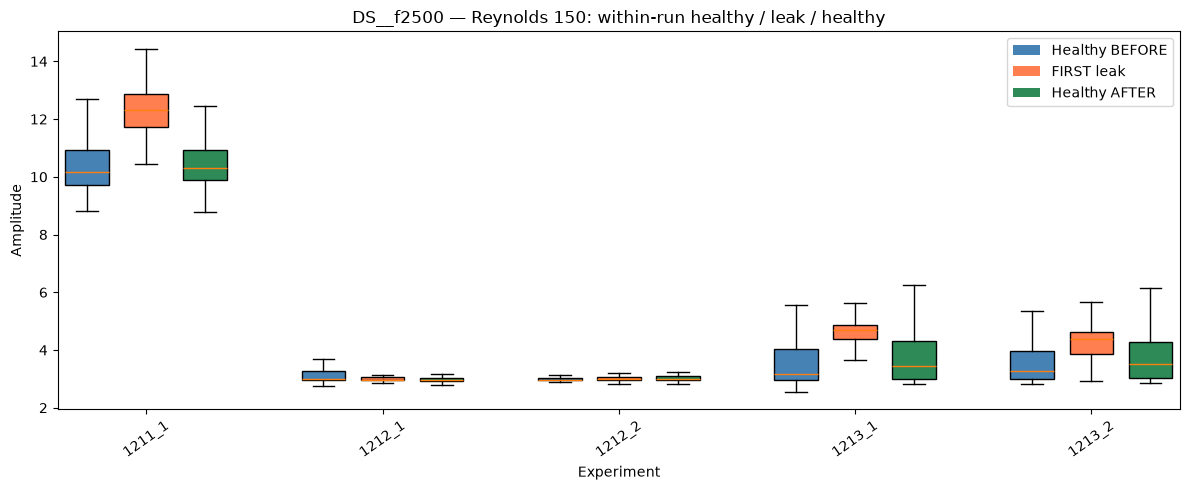

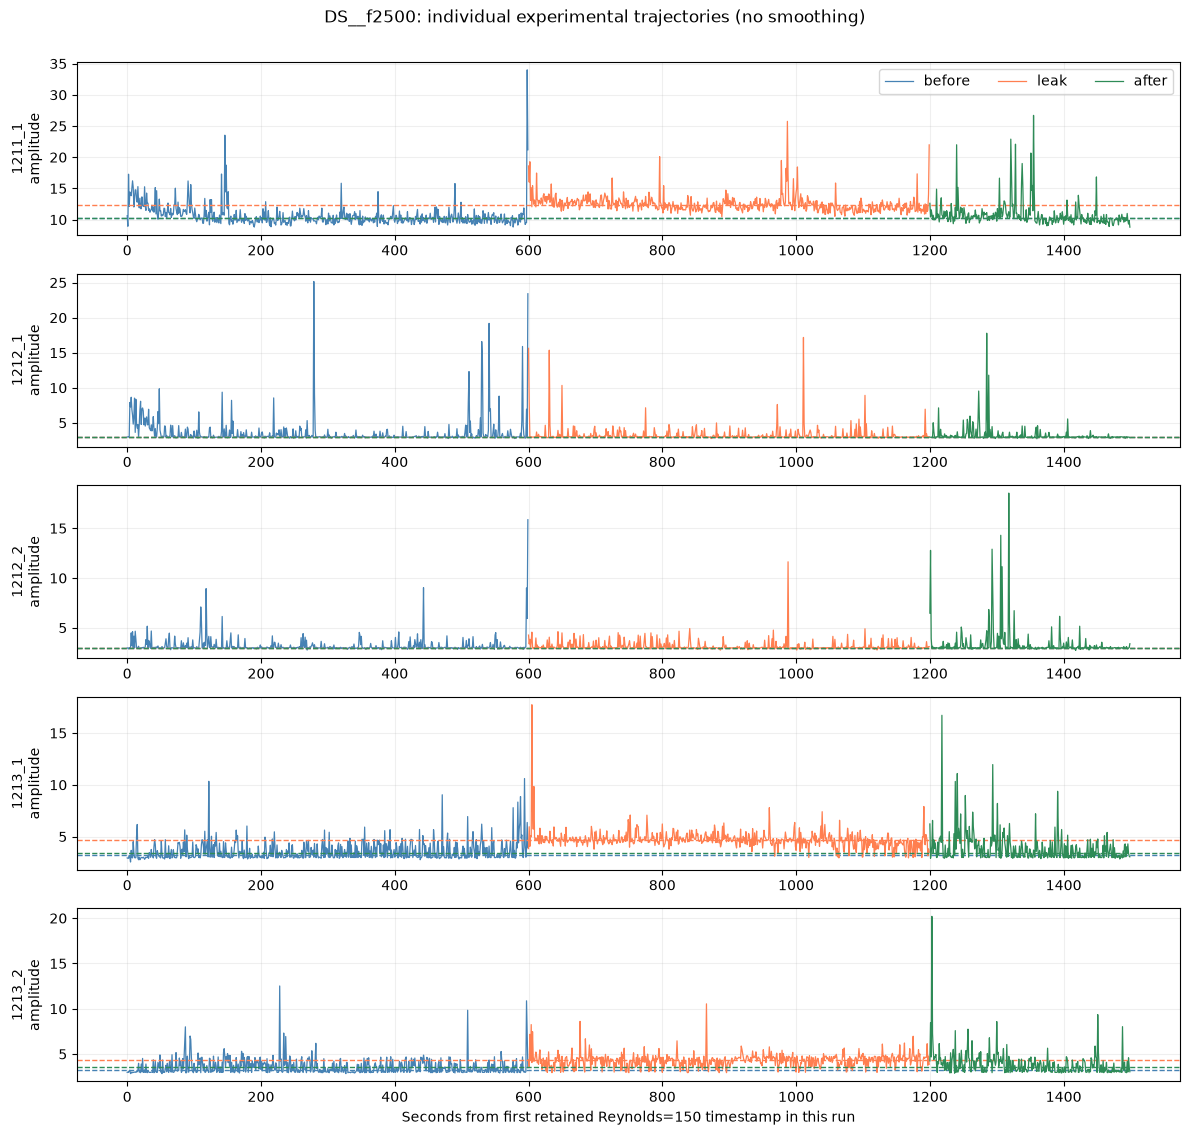

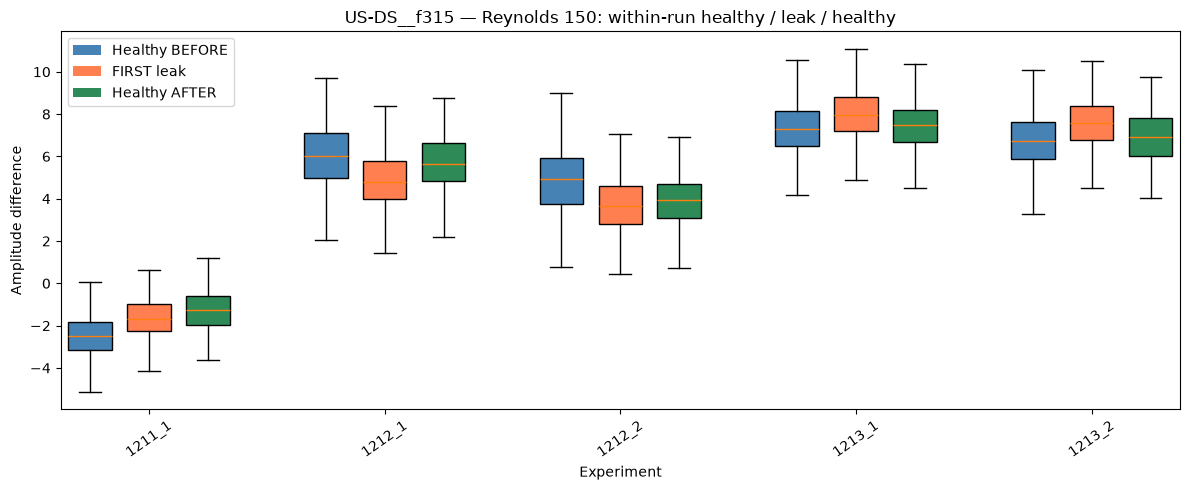

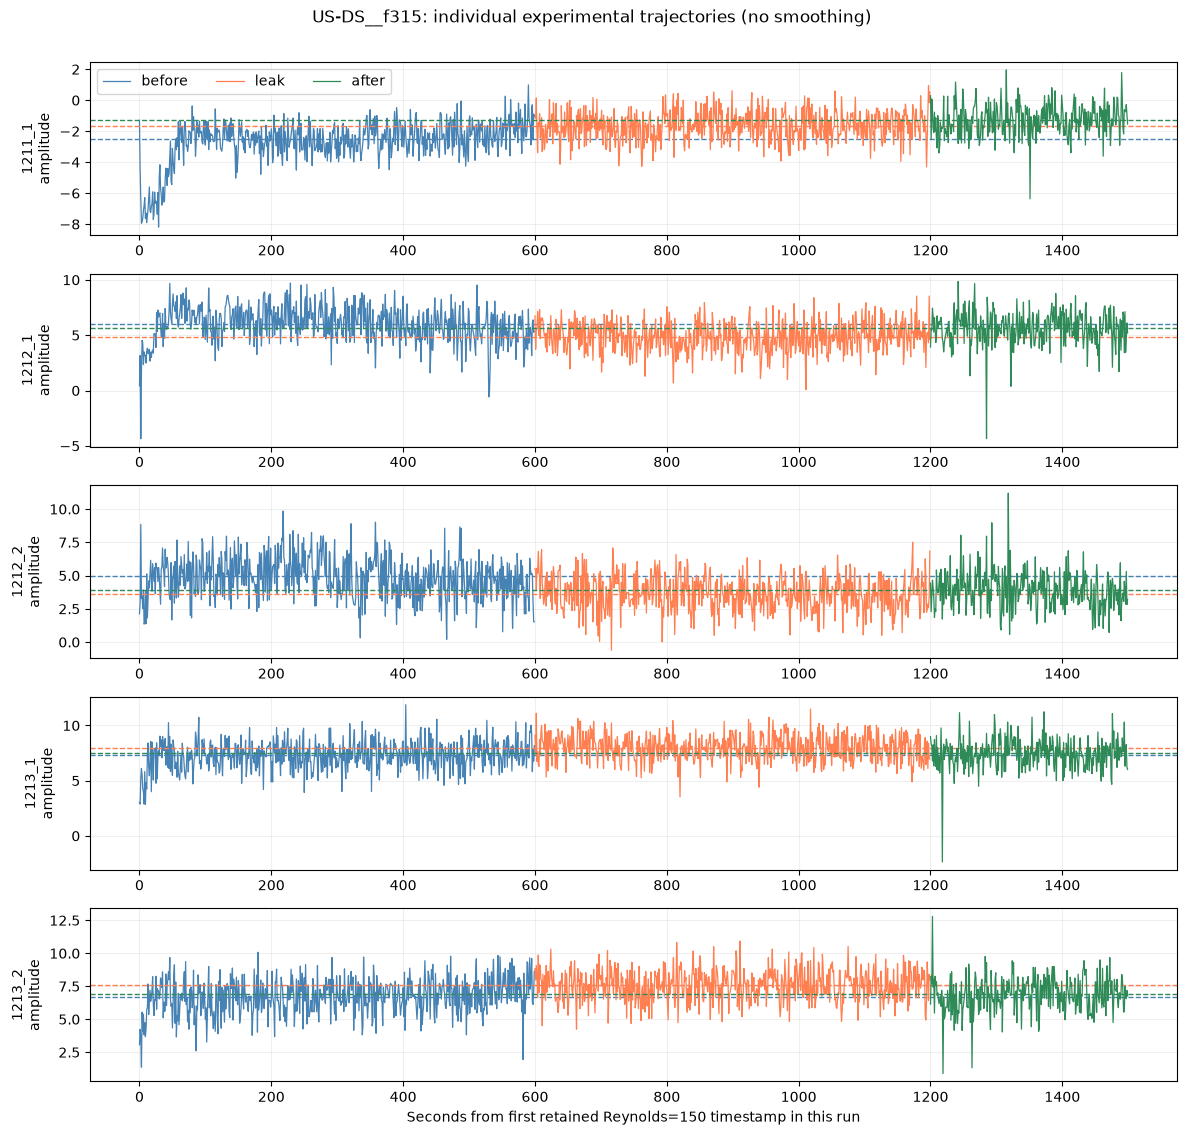

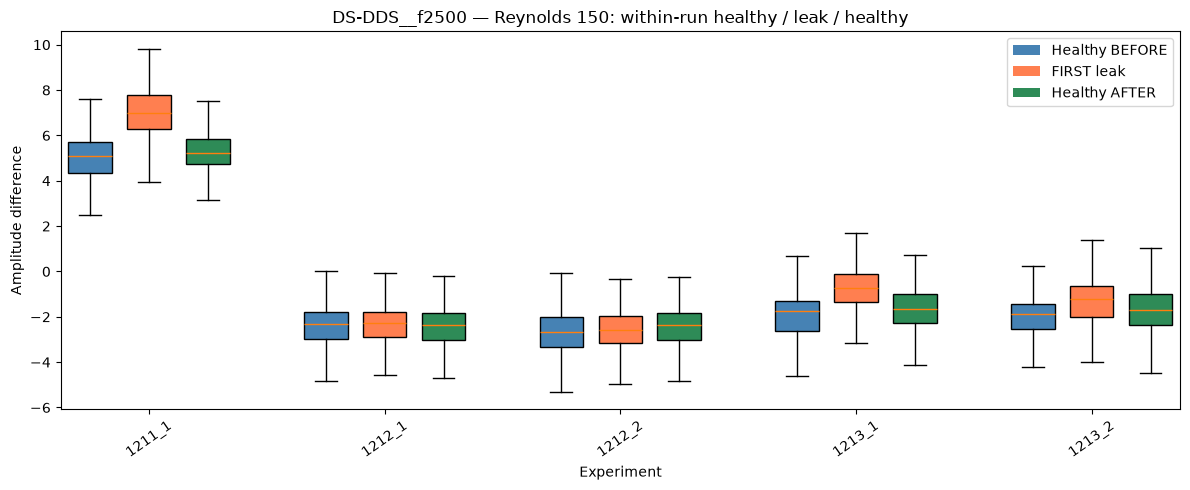

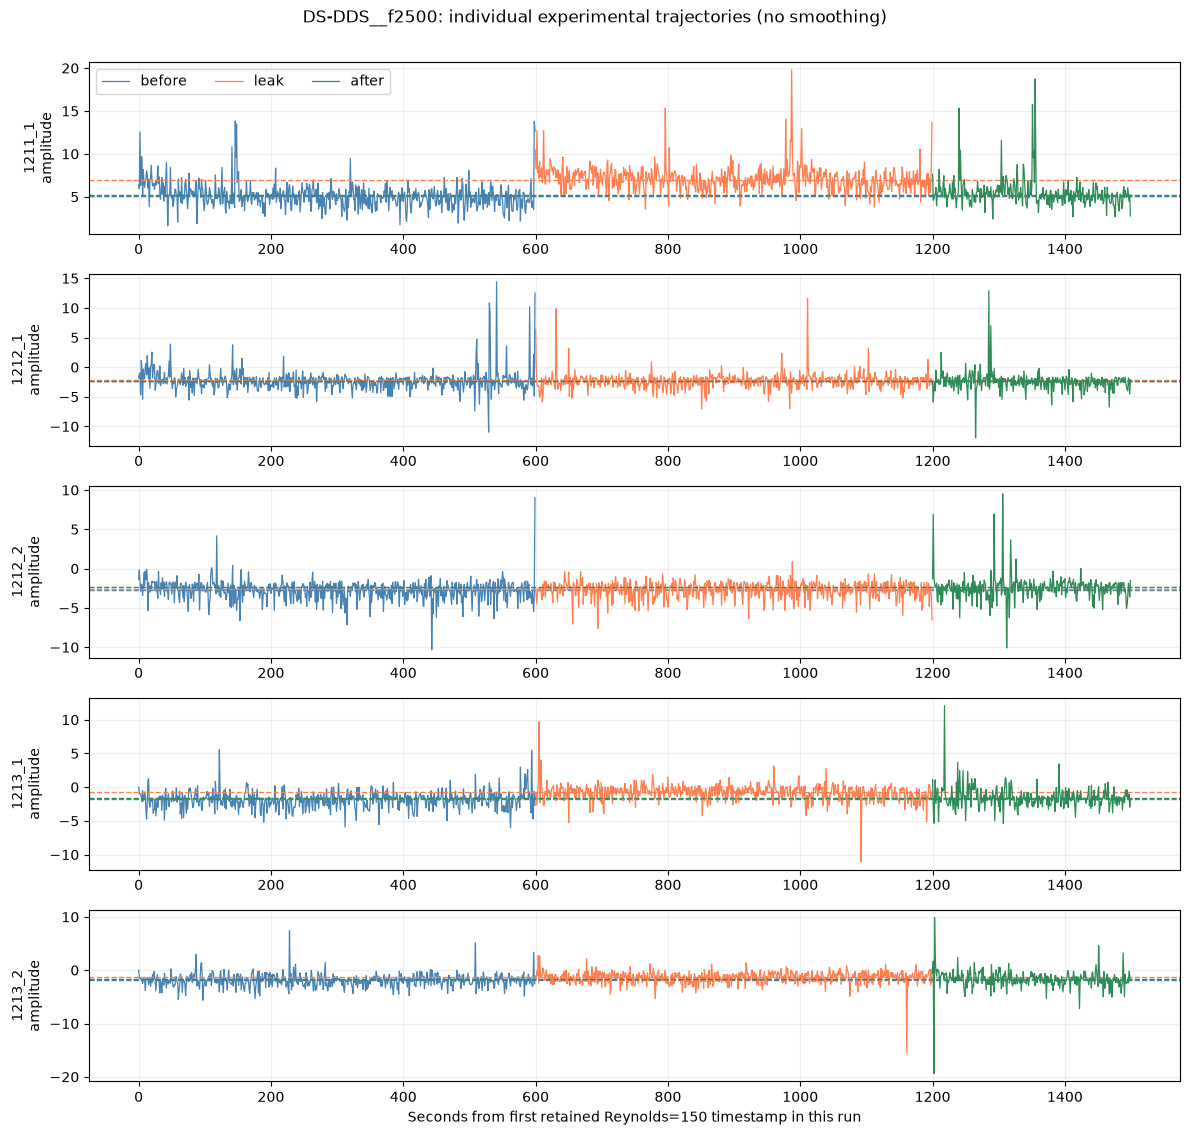

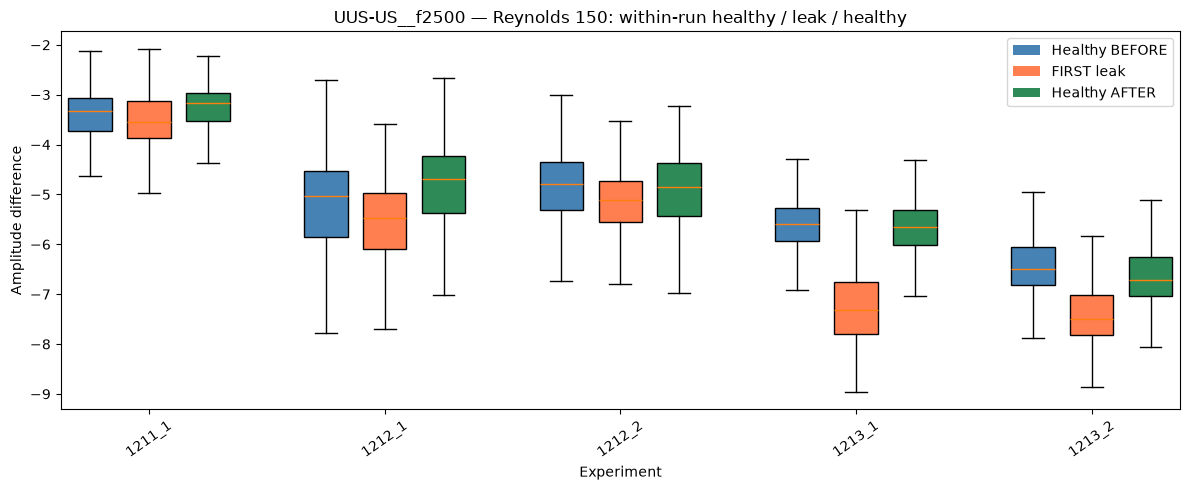

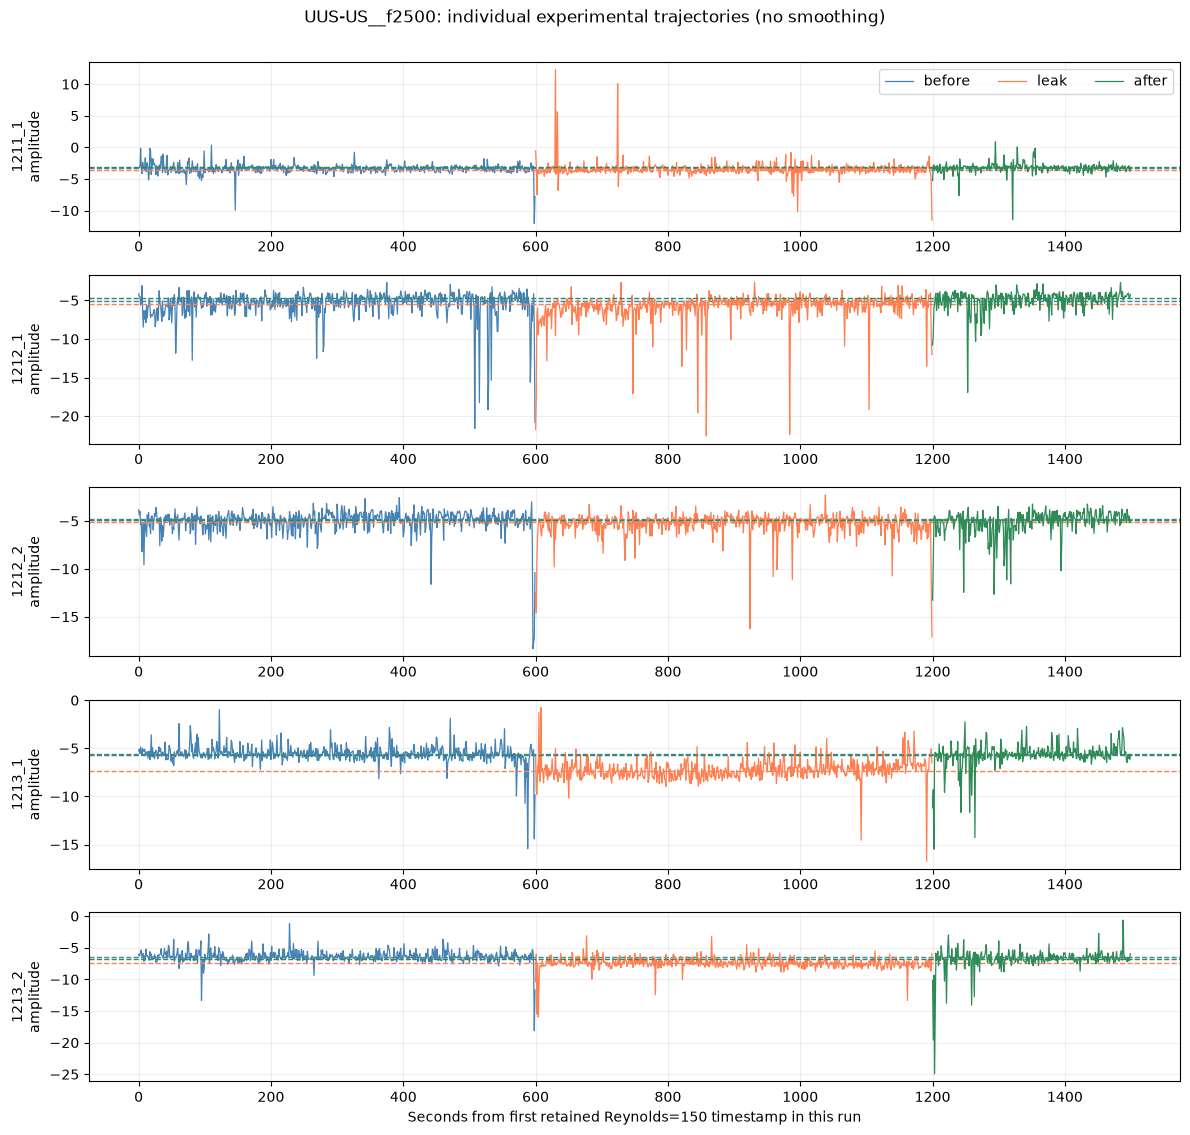

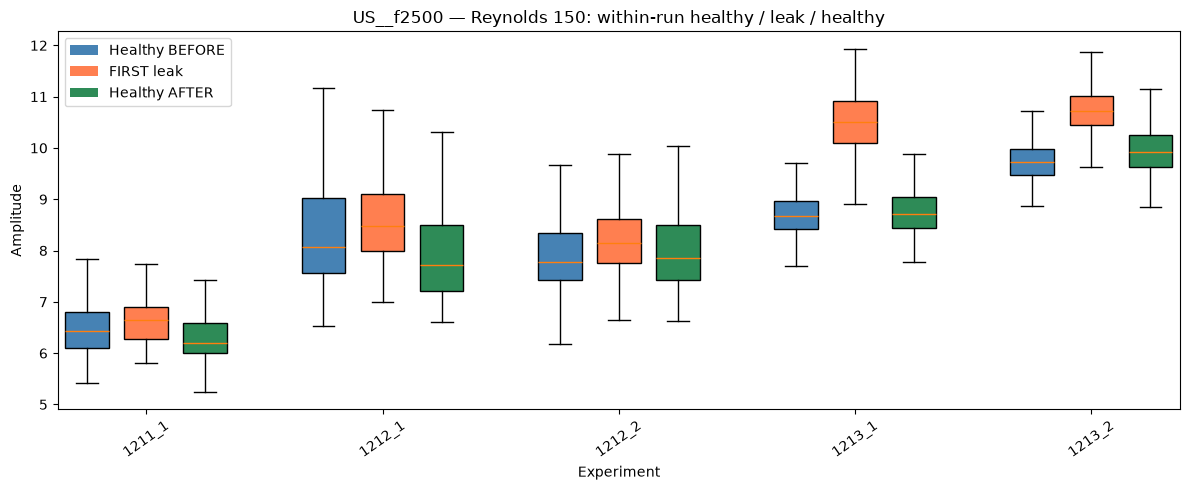

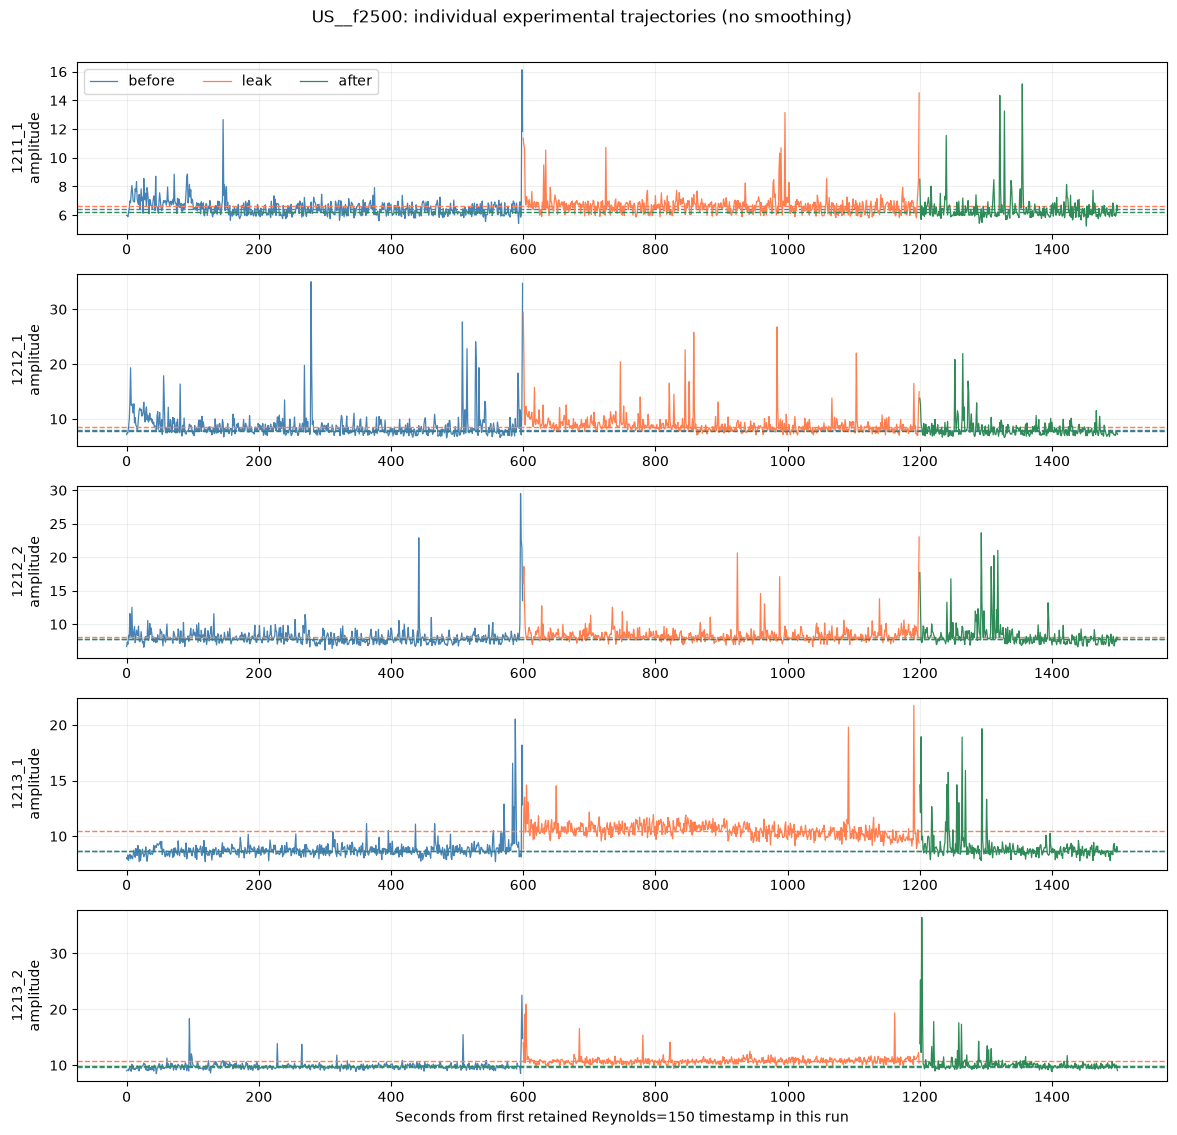

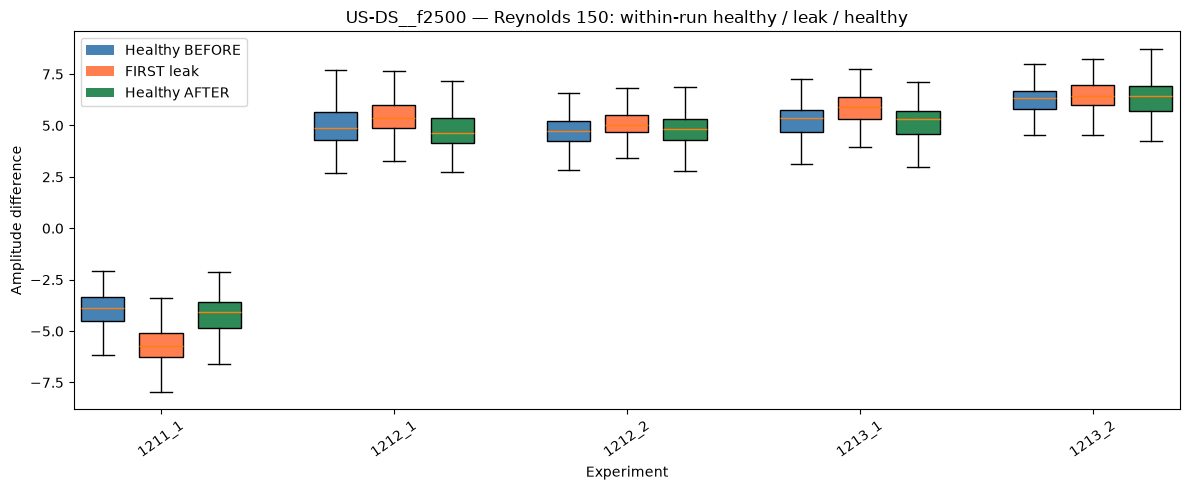

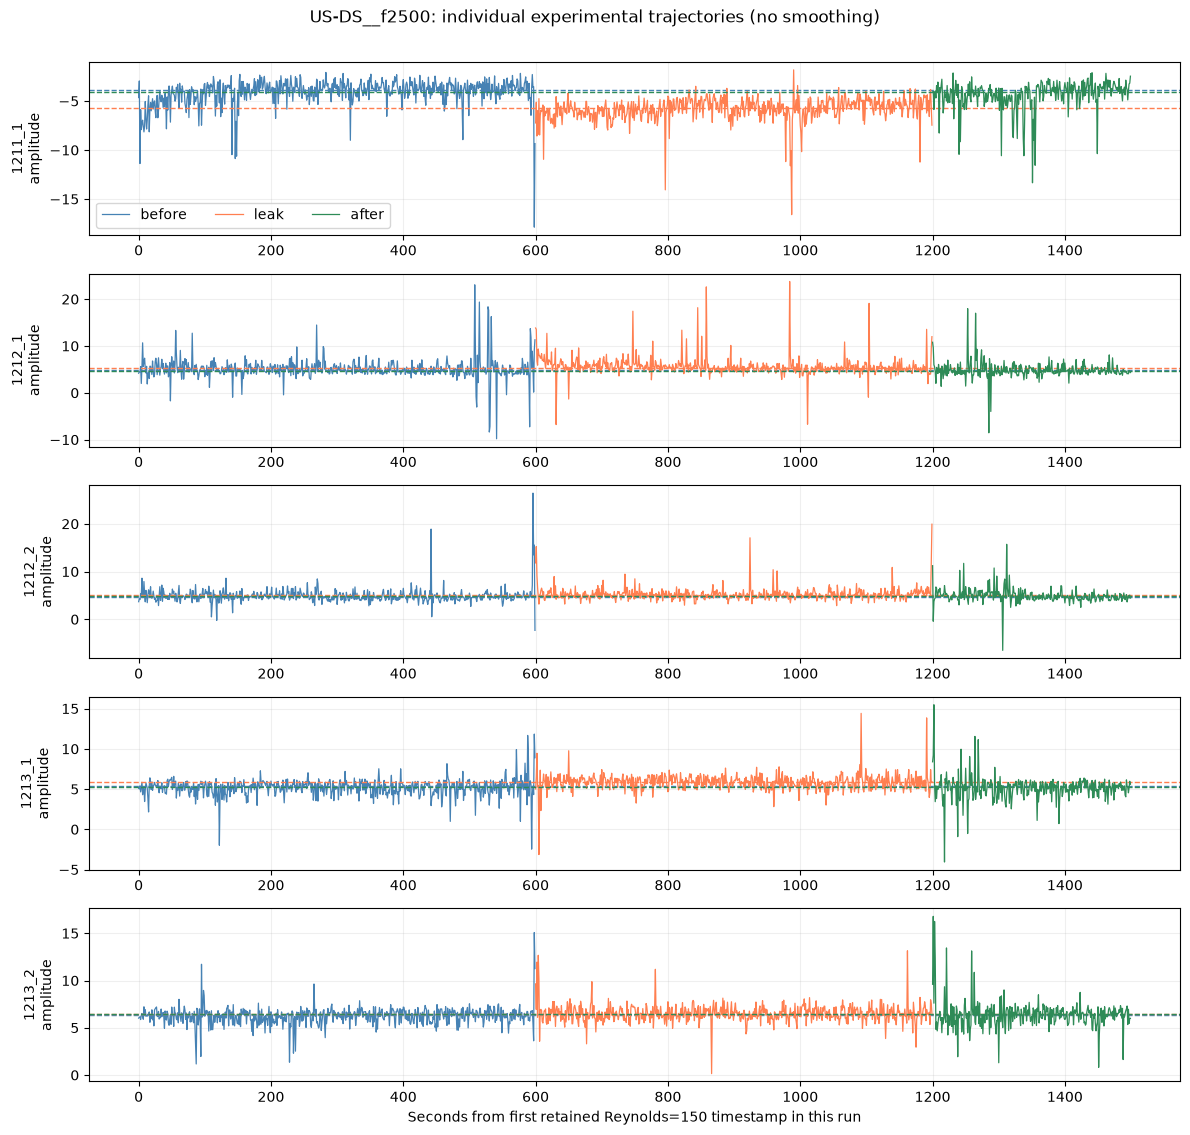

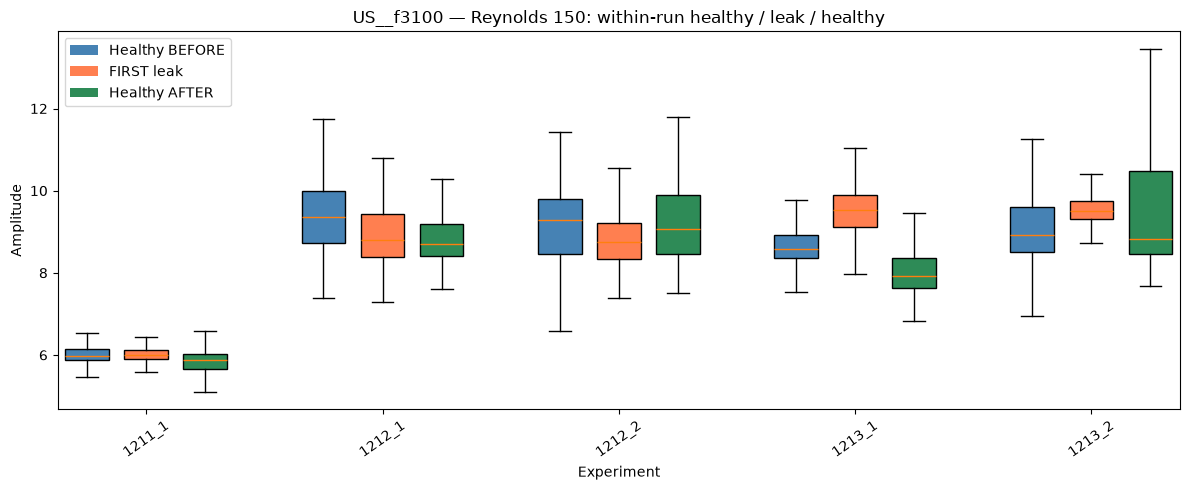

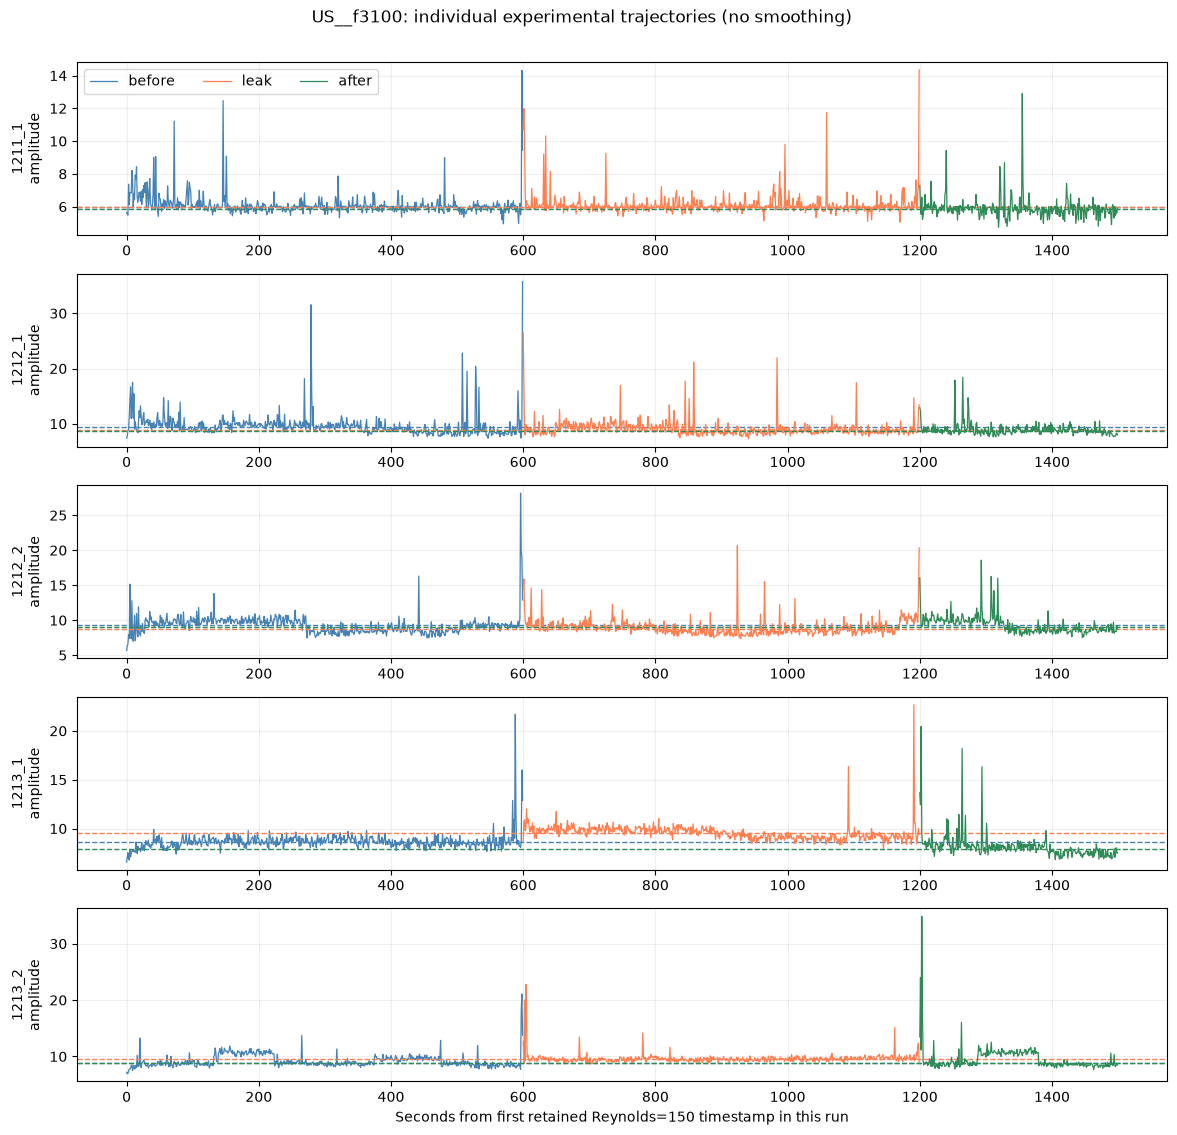

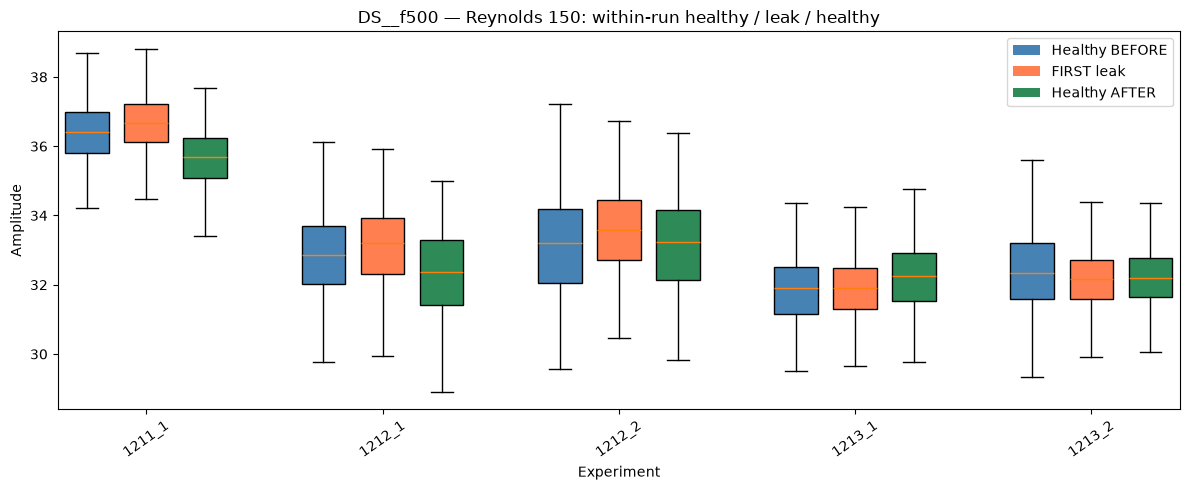

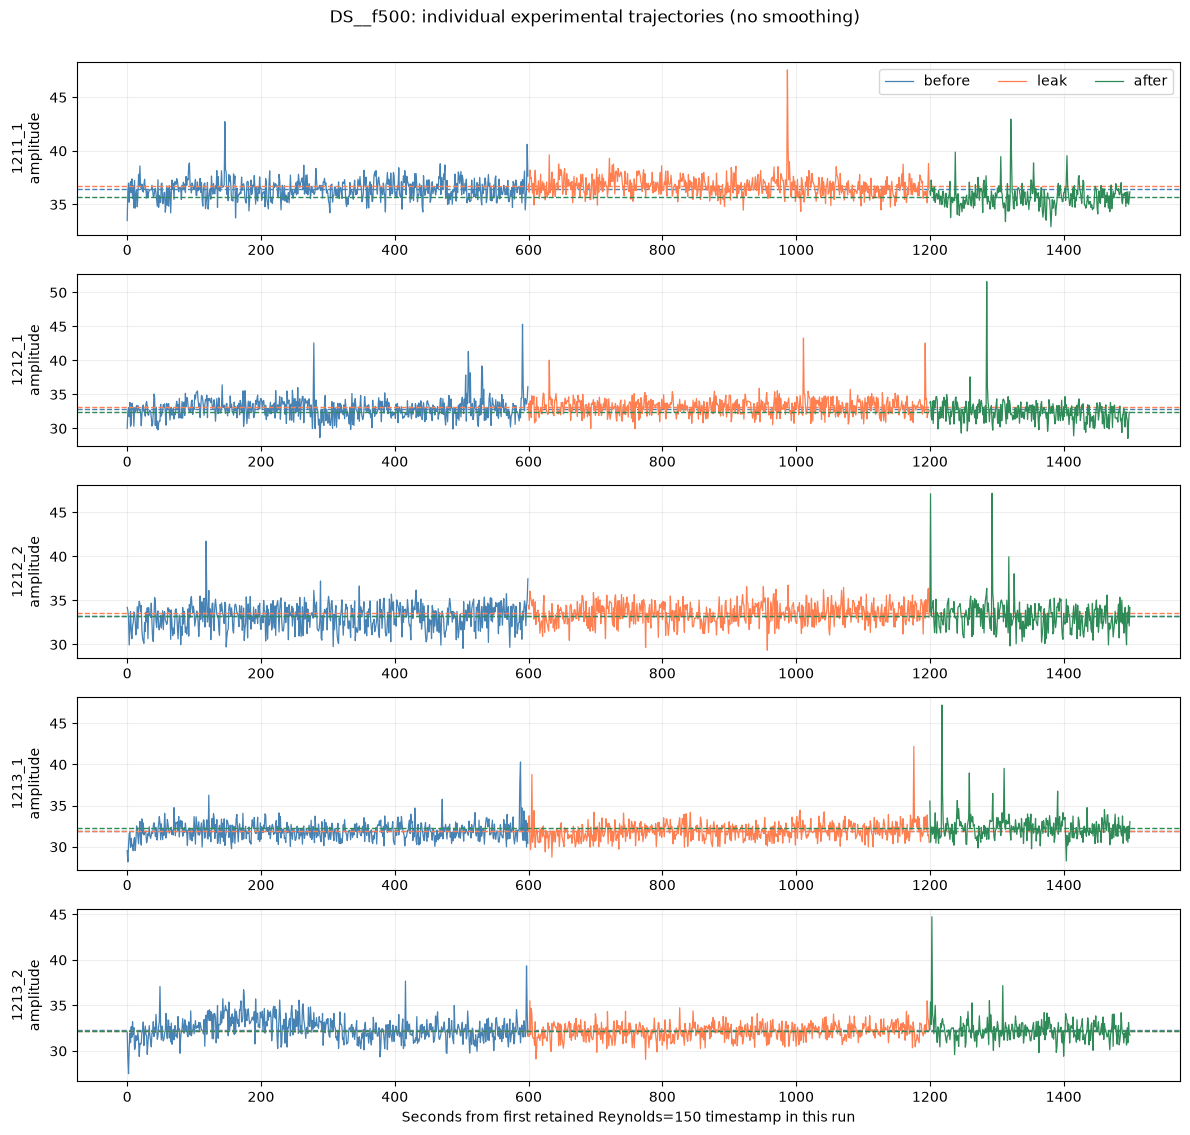

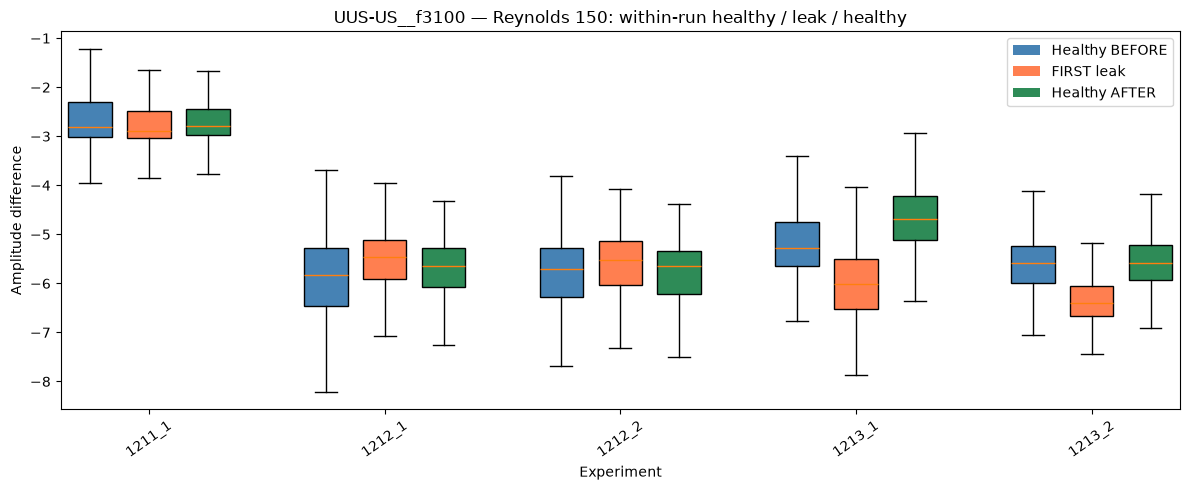

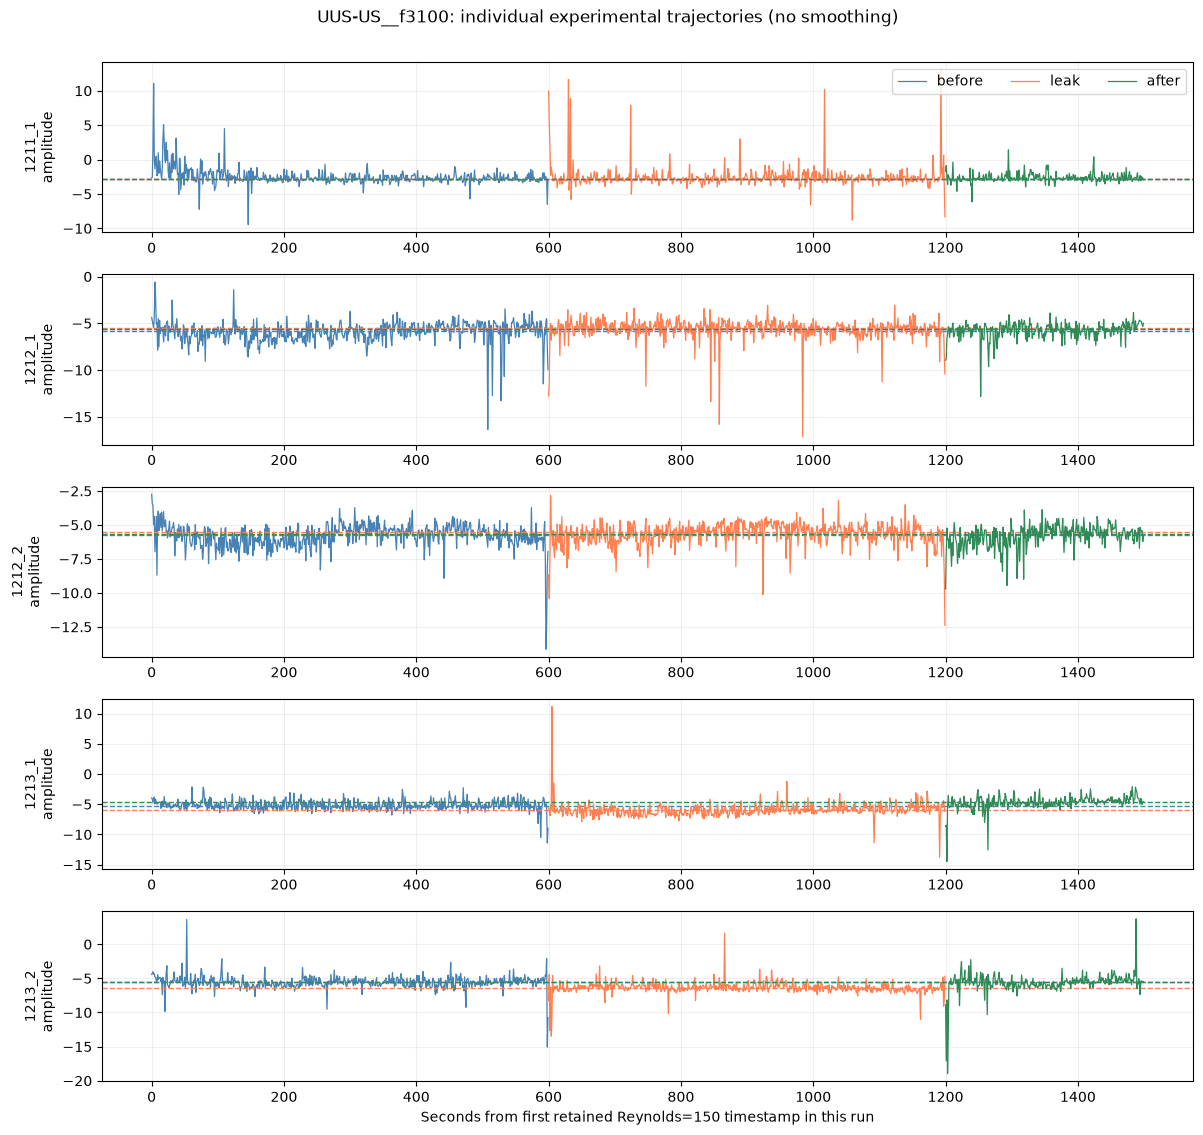

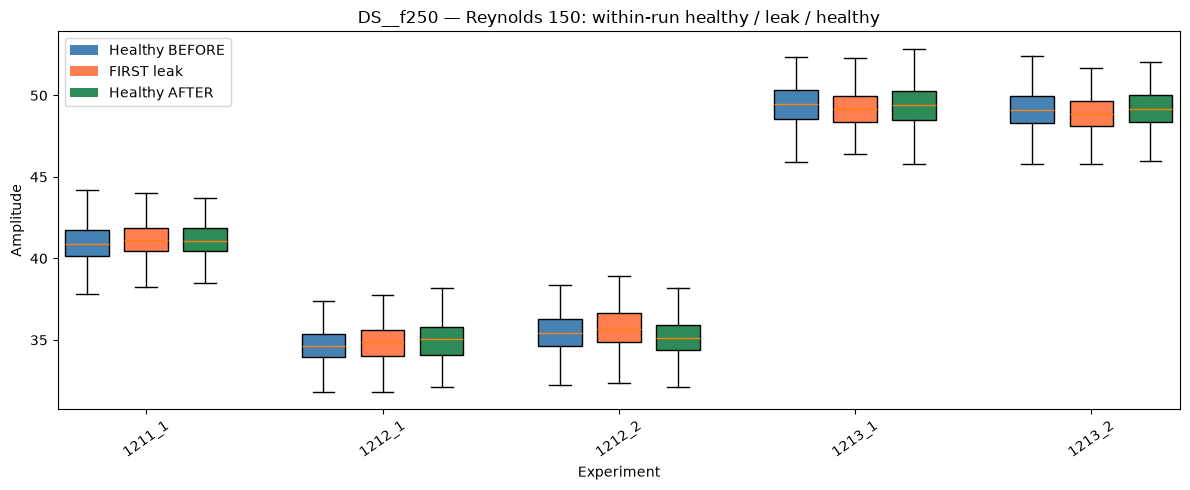

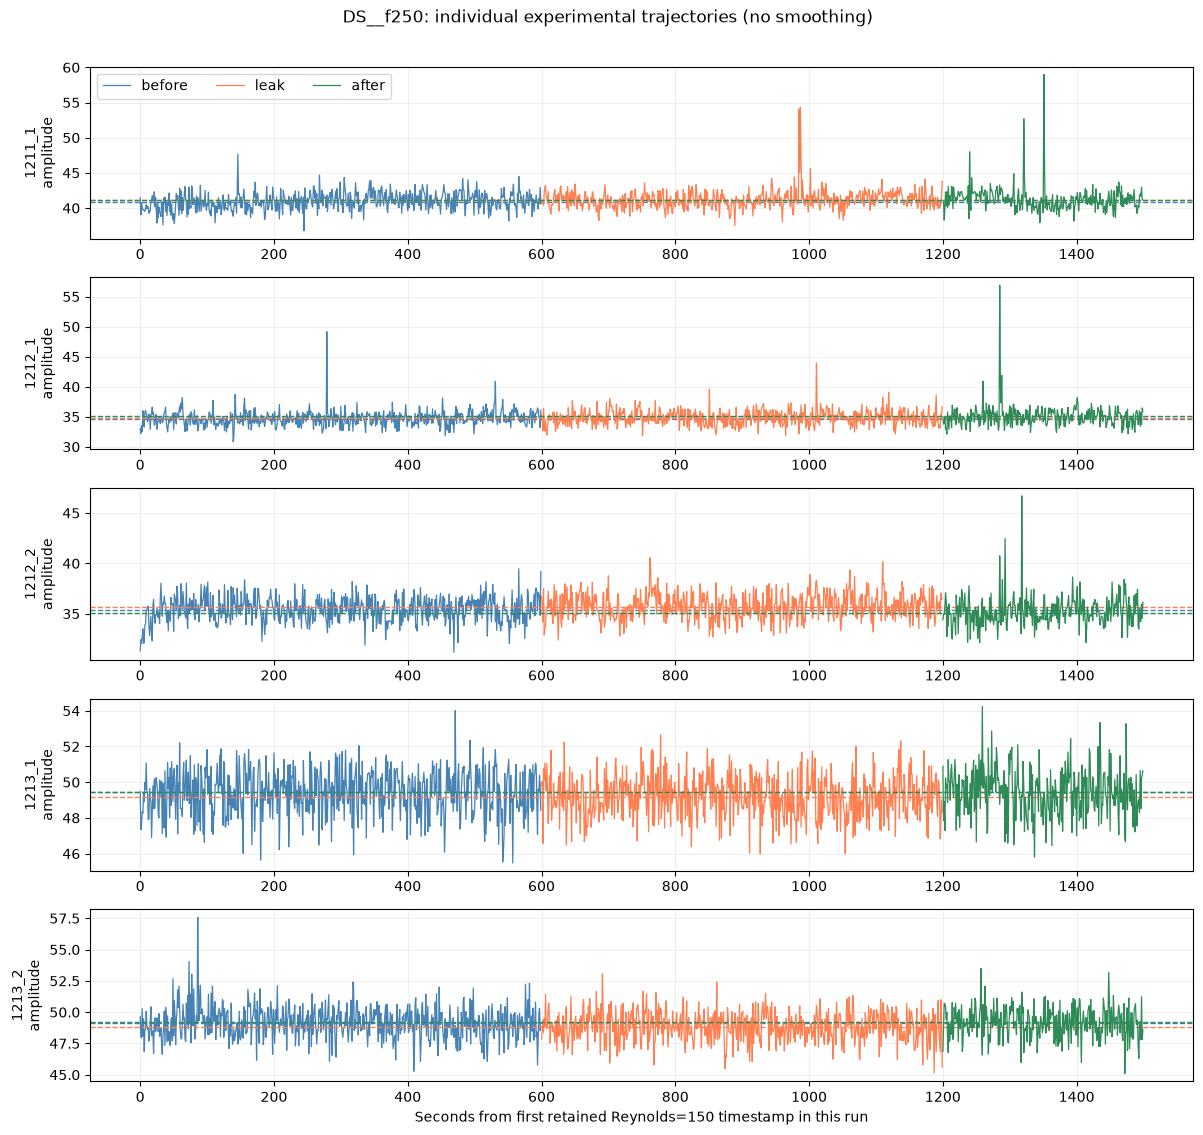

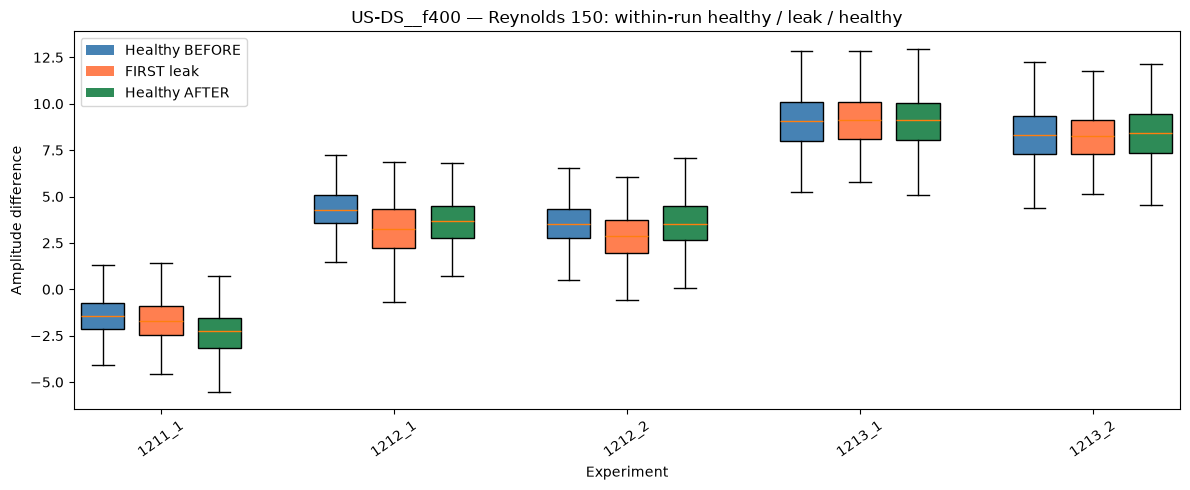

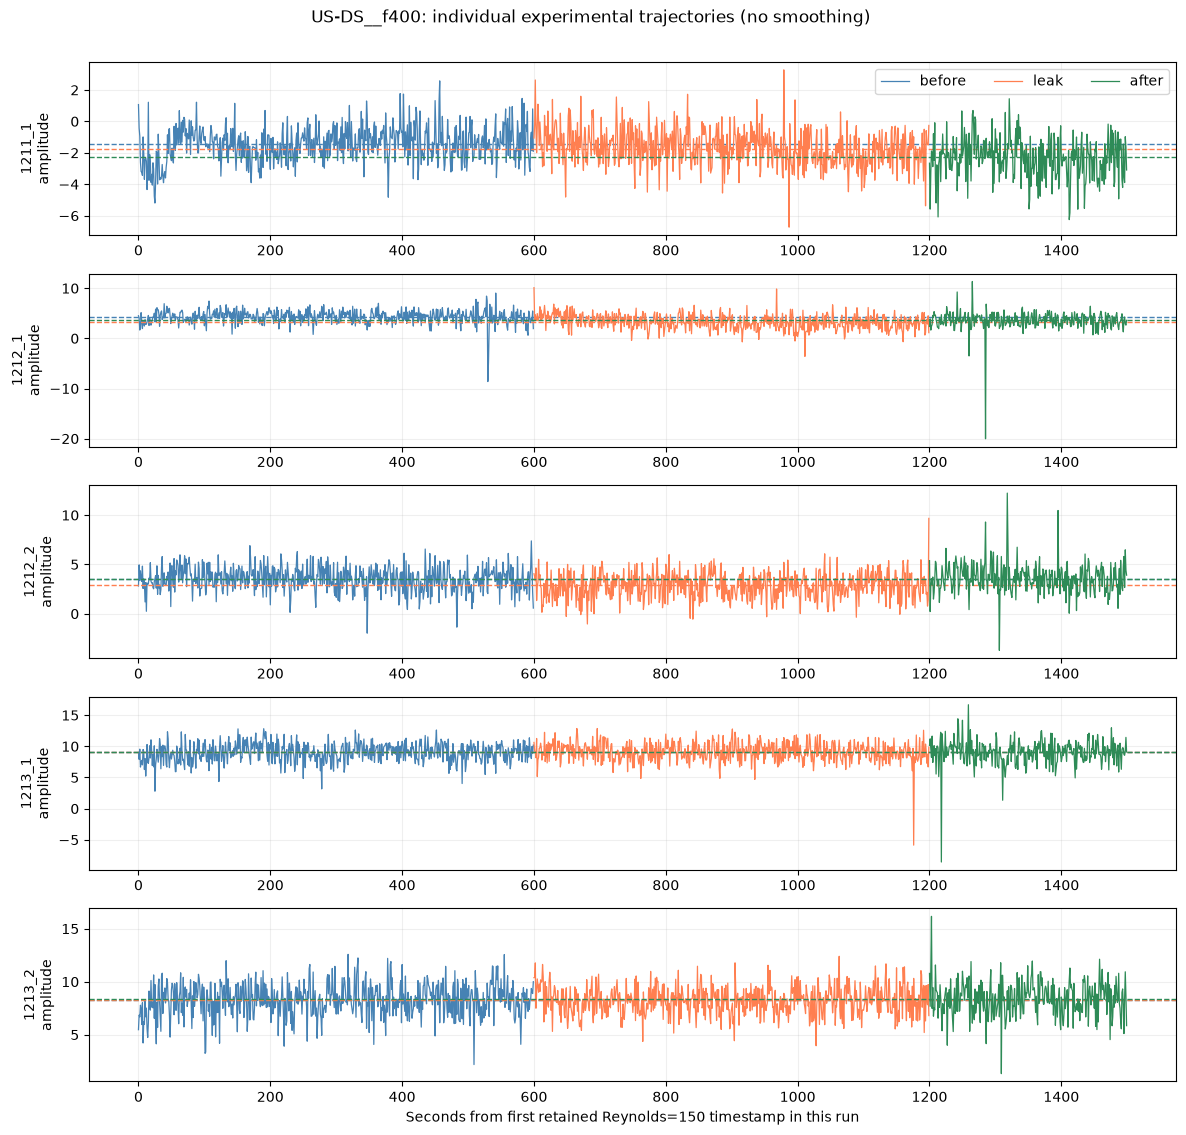

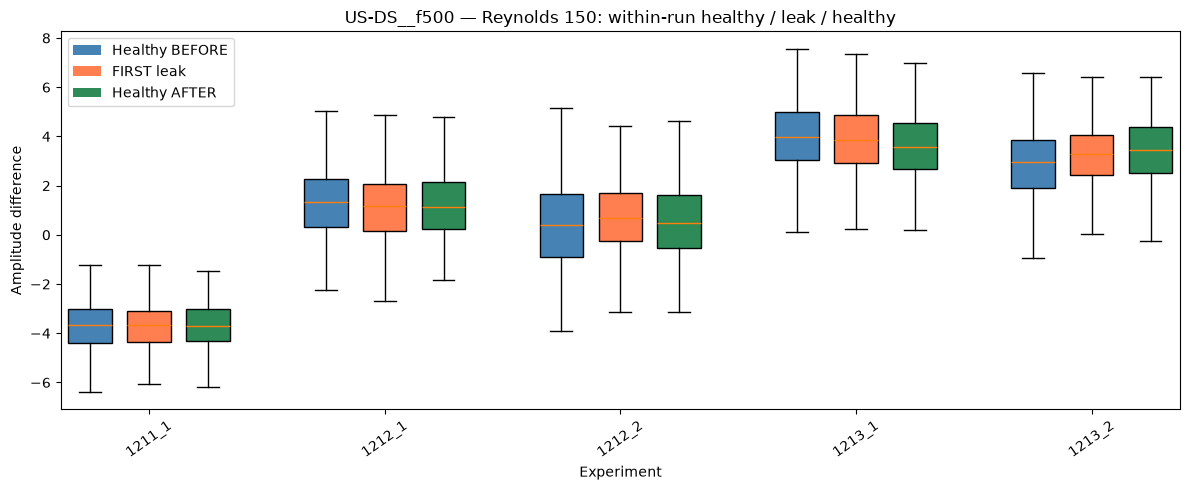

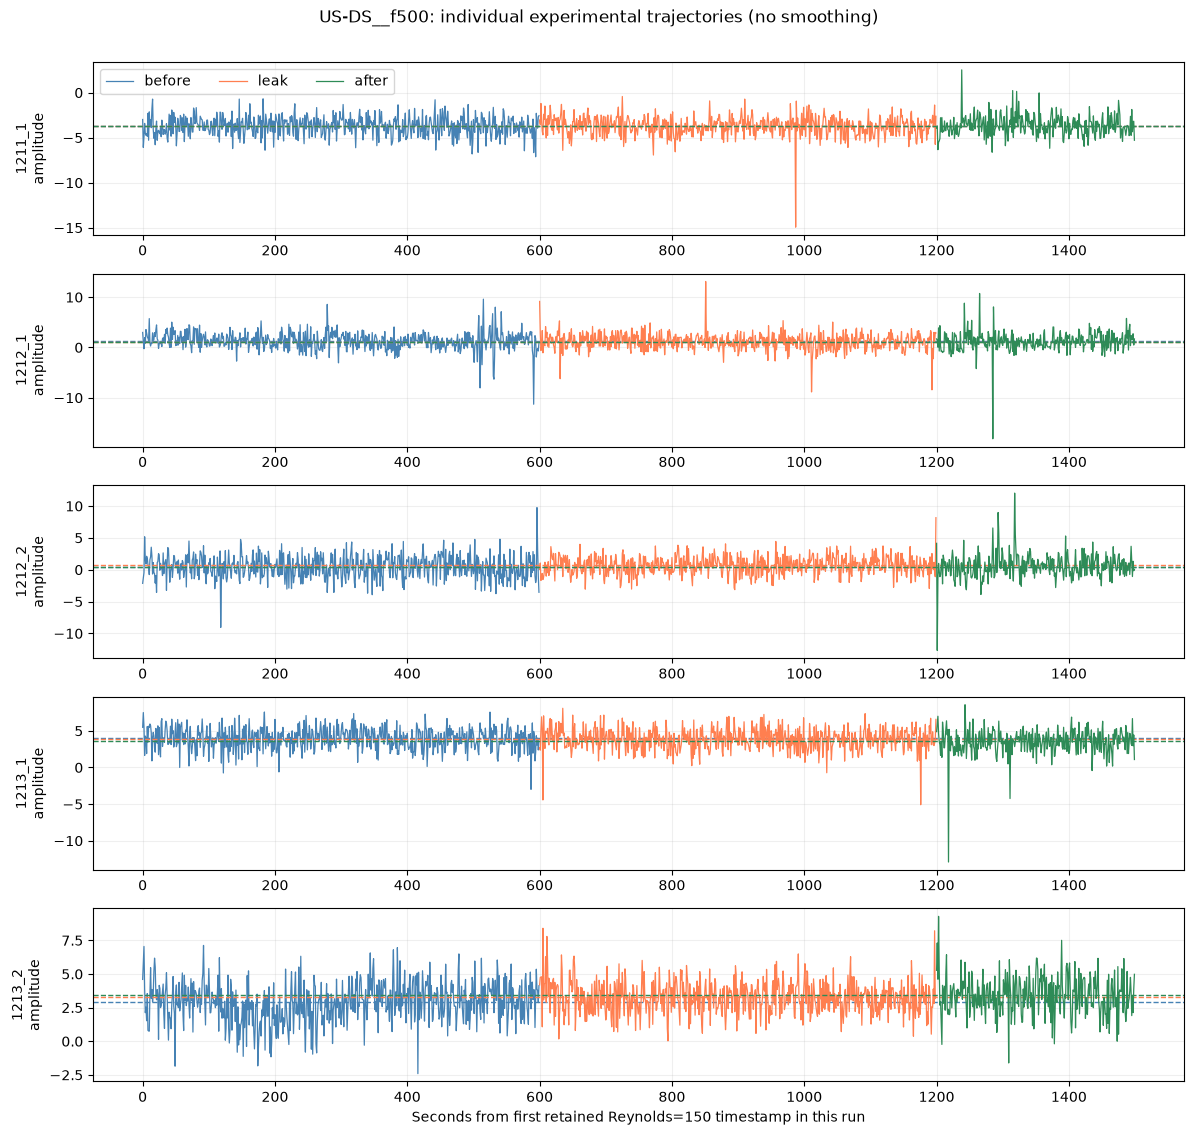

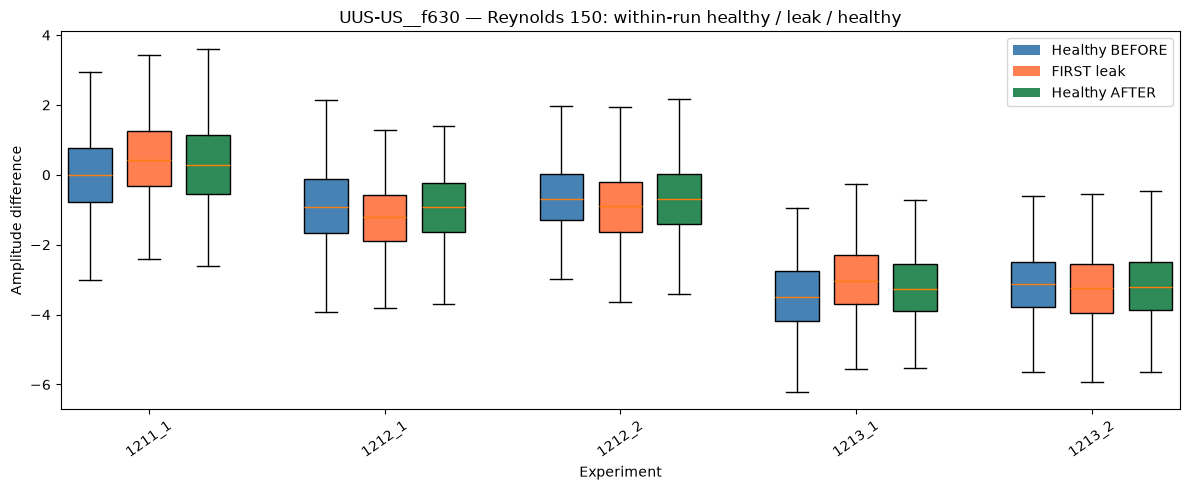

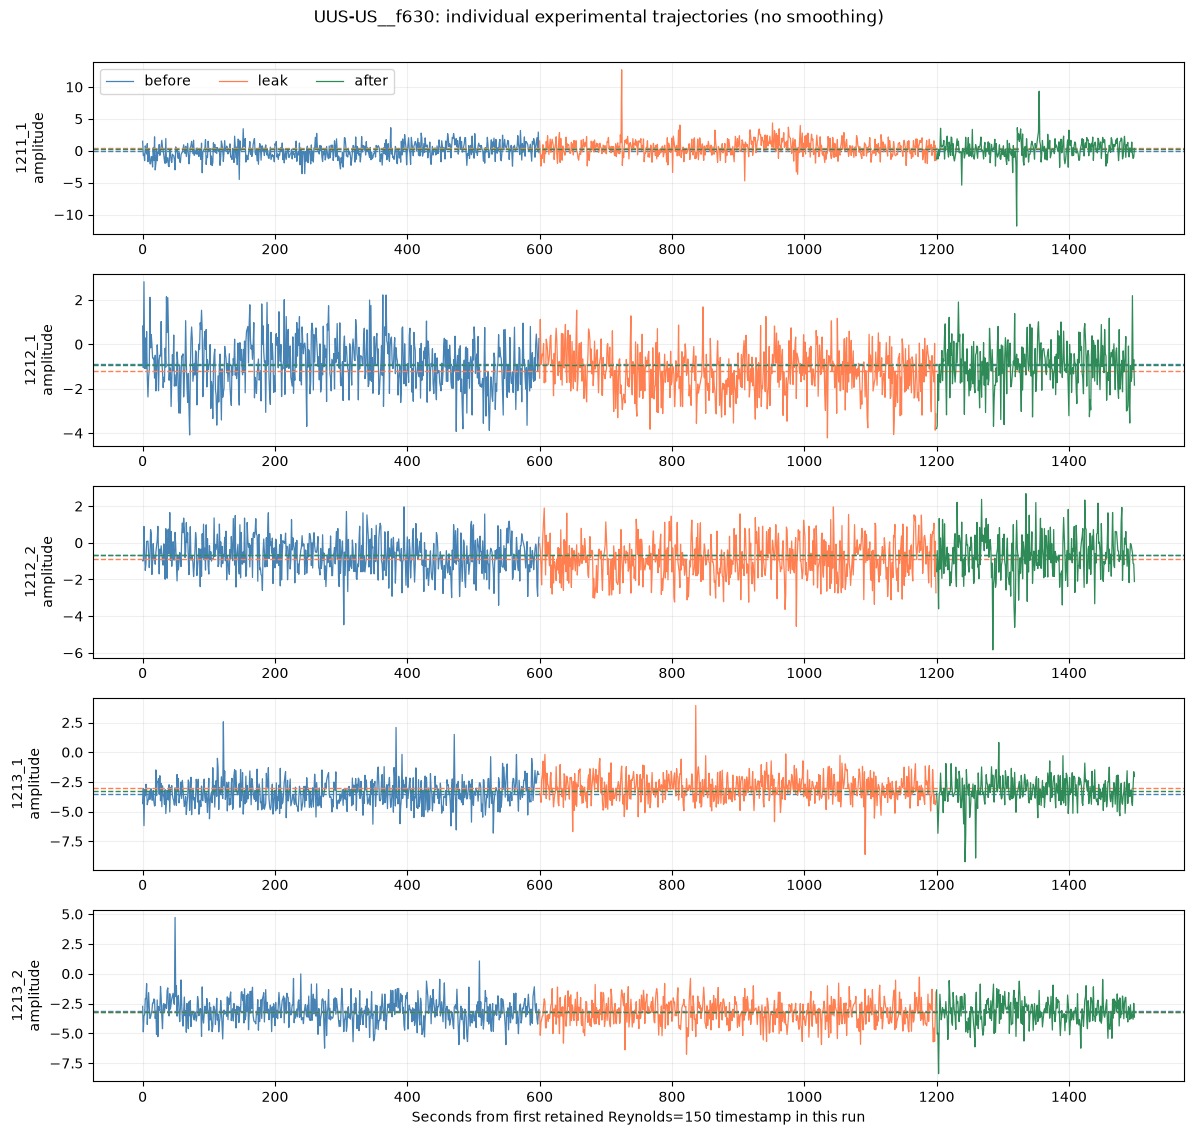

In [7]:
plot_features = list(dict.fromkeys([
    *ranking['feature'].head(TOP_N_PLOTS),
    *(f for f in IMPORTANT_FEATURES if f in FEATURES)
]))
print('Features plotted:',plot_features)
print('Feature ranking CSV contains:',len(ranking),'features')
legend = [Patch(facecolor='steelblue',label='Healthy BEFORE'),
          Patch(facecolor='coral',label='FIRST leak'),
          Patch(facecolor='seagreen',label='Healthy AFTER')]
runs = sorted(wide.run_id.unique())
colors={'before':'steelblue','leak':'coral','after':'seagreen'}
for feature in plot_features:
    fig,ax=plt.subplots(figsize=(max(12,len(runs)*2.15),5))
    has_data=False
    for i,run in enumerate(runs):
        rr=wide.loc[wide.run_id.eq(run)]
        for offset,phase in enumerate(PHASES):
            values=rr.loc[rr.phase.eq(phase),feature].dropna()
            if values.empty:
                continue
            has_data=True
            ax.boxplot(values.to_numpy(),positions=[4*i+offset],widths=.74,
                       patch_artist=True,showfliers=False,
                       boxprops={'facecolor':colors[phase]})
    ax.set_xticks([4*i+1 for i in range(len(runs))],runs,rotation=35)
    ax.set_ylabel('Amplitude' if '-' not in feature.split('__')[0] else 'Amplitude difference')
    ax.set_xlabel('Experiment')
    ax.set_title(f'{feature} — Reynolds 150: within-run healthy / leak / healthy')
    ax.legend(handles=legend,loc='best')
    fig.tight_layout()
    fig.savefig(OUT/f'boxplot_{feature}.png',dpi=150,bbox_inches='tight')
    plt.show()
    if not has_data:
        print('No values in any phase for',feature)

    fig,axes=plt.subplots(len(runs),1,figsize=(12,max(3,len(runs)*2.25)),sharex=False)
    axes=np.atleast_1d(axes)
    for ax,run in zip(axes,runs):
        rr=wide.loc[wide.run_id.eq(run)].sort_values('timestamp')
        t0=rr.timestamp.min()
        for phase in PHASES:
            p=rr.loc[rr.phase.eq(phase),['timestamp',feature]].dropna()
            if not p.empty:
                xs=(p.timestamp-t0).dt.total_seconds().to_numpy()
                ax.plot(xs,p[feature].to_numpy(),color=colors[phase],lw=.9,label=phase)
                ax.axhline(float(p[feature].median()),color=colors[phase],lw=1,linestyle='--')
        ax.set_ylabel(f'{run}\namplitude')
        ax.grid(alpha=.2)
    axes[0].legend(loc='best',ncol=3)
    axes[-1].set_xlabel('Seconds from first retained Reynolds=150 timestamp in this run')
    fig.suptitle(f'{feature}: individual experimental trajectories (no smoothing)',y=1.005)
    fig.tight_layout()
    fig.savefig(OUT/f'trace_{feature}.png',dpi=150,bbox_inches='tight')
    plt.show()

## 7. Interpretation and verification checklist

- **What strong sensitivity looks like:** leak median lies beyond **both** healthy medians, by a sizeable amount relative to temporal fluctuations, in several runs with the **same direction**. A candidate should also be inspected for healthy plateau return and frequency/probe consistency.
- **Not a test of a causal effect:** no nonleaking simultaneous control; the healthy-after phase may retain physical effects of the leak or have different operating history. Curved drift between the two healthy phases can mimic an excursion.
- **Not a significance test:** there are only five independent runs. A two-sided sign test requires more than five runs to attain p < 0.05 even for unanimity; do not use timestamp-level t-tests or claim a p-value from this ranking.
- **Respect probe geometry:** the leak is known to occur between US and DS. `US-DS` is the directly bracketing spatial contrast. An acoustic response in `UUS-US` or `DS-DDS` alone does not locate the leak.
- **No automatic channel rejection:** a large healthy drift `abs(A-B)` or large between-run baseline SD is displayed for review; it is not silently filtered away.
- **File contents:** source phases, per-run run statistics, complete run-feature scores, complete feature ranking, frequency ranking, within-channel rankings (including `US-DS`), heatmap, boxplots and raw traces.

**No modifications** were made to `healthy_frequency_reproducibility_v2.ipynb`, `first_leak_frequency_analysis_DiD_posthealthy.ipynb`, original CSVs, or extractor scripts.